# Dual-representation CNNs for classifying simulated fast radio bursts

This notebook compares frequency-time (FT), dispersion measure-time (DM), and dual-input convolutional neural networks (CNNs), alongside classical baseline classifiers, for separating simulated **fast radio bursts (FRBs)** from **radio-frequency interference (RFI)** and background samples.

Simulated FRBs are injected into HERA background arrays, each sample is converted to FT and DM-time images, and the models are evaluated on a development test split and on a separate final holdout set. Tables, figures, diagnostics and model summaries are written to `results/`.

**Pipeline overview**
- background arrays are split into training, validation and test groups before any injection, with split-leakage checks
- DM-time inputs are generated from the injected FT image, and a DM-transform check confirms that injection changes the DM-time map
- Python, NumPy and Keras seeding; CNNs are trained across three seeds with early stopping
- confusion matrices, ROC and precision-recall curves, and SNR-efficiency plots for the three CNNs on the final holdout set
- a hard-negative stress test and an explicit claim-boundary table

**Scope:** this is a controlled injection benchmark. It does **not** establish a confirmed astrophysical FRB detection; that requires validation on real filterbank data.

## 1. Imports and reproducibility

This cell imports the scientific Python packages used throughout (NumPy, pandas, scikit-learn, XGBoost, TensorFlow/Keras), seeds all random number generators, and creates the output folders. `google.colab` is imported to mount Google Drive, where the HERA data file is stored. No online download utilities are used.

In [58]:
import os
import json
import glob
import pickle
import random
import warnings
import math
import datetime
from pathlib import Path
from google.colab import drive

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve,
    confusion_matrix,
    accuracy_score,
    precision_recall_fscore_support,
)

warnings.filterwarnings("ignore")

SEED = 123


def set_all_seeds(seed):
    """Seed Python, NumPy, and TensorFlow/Keras for reproducible runs."""
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)


# Seed everything once at import time. The multi-seed CNN loop reseeds per seed.
set_all_seeds(SEED)

# Ask TensorFlow for deterministic ops so a fixed seed reproduces bit-for-bit.
# Some Colab/GPU backends do not support this for every op, so it is best-effort.
try:
    tf.config.experimental.enable_op_determinism()
except Exception as _e:
    print("Note: deterministic ops unavailable on this backend:", _e)

OUTPUT_DIR = Path("results")
FIG_DIR = OUTPUT_DIR / "figures"
TABLE_DIR = OUTPUT_DIR / "tables"
TEXT_DIR = OUTPUT_DIR / "paper_text"
for d in [OUTPUT_DIR, FIG_DIR, TABLE_DIR, TEXT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print("Ready. Output folder:", OUTPUT_DIR.resolve())
print("TensorFlow:", tf.__version__)


Ready. Output folder: /content/results
TensorFlow: 2.21.0


## 2. Configuration

Dataset sizes, injection ranges, model settings and random seeds are defined here. The injection grid spans 1.10-1.50 GHz with 20 ms time bins, so that a dispersed sweep fits inside the 128-sample image window. HERA observes at much lower frequencies (roughly 50-250 MHz), where dispersion delays are far longer, so applying the pipeline at native HERA frequencies would require rescaling the time window and DM range.

In [59]:
CONFIG = {
    # Dataset size. Increase after the session if runtime is acceptable.
    "N_BACKGROUND_BANK": 360,
    "TRAIN_POS": 160,
    "TRAIN_NEG": 160,
    "VAL_POS": 50,
    "VAL_NEG": 50,
    "TEST_POS": 80,
    "TEST_NEG": 80,

    # Image sizes. These are session-safe and still preserve the core morphology.
    "NFREQ": 128,
    "NTIME": 128,
    "N_DM_TRIALS": 40,

    # Fallback observing grid.
    # GHz and milliseconds are used below, so the dispersion constant is 4.148808.
    "FREQ_LOW_GHZ": 1.10,
    "FREQ_HIGH_GHZ": 1.50,
    "DT_MS": 20.0,

    # Injection parameters.
    "DM_RANGE": (80.0, 1000.0),
    "SNR_RANGE": (2.5, 8.0),
    "WIDTH_BINS_RANGE": (1.0, 3.0),

    # DM-time transform.
    "DM_TRIAL_MIN": 0.0,
    "DM_TRIAL_MAX": 1200.0,

    # Lightweight pipeline unit check. Only this many positive examples per split
    # are transformed twice (background-only and injected) to avoid doubling runtime.
    "DM_DEBUG_EXAMPLES_PER_SPLIT": 5,

    # Baseline model settings.
    "RANDOM_FOREST_TREES": 180,
    "RANDOM_FOREST_MAX_DEPTH": 10,
    "XGB_ESTIMATORS": 150,
    "XGB_MAX_DEPTH": 5,
    "XGB_LEARNING_RATE": 0.1,

    # CNN training.
    "CNN_EPOCHS": 35,
    "CNN_BATCH_SIZE": 32,
    "CNN_LEARNING_RATE": 1e-3,
    "CNN_EARLY_STOP_PATIENCE": 7,
    "SEED_LIST": [123, 7, 2024],

    # Local background loading.
    # If no compatible local files are found, the notebook falls back safely.
    "USE_LOCAL_BACKGROUND_ARRAYS": True,
    "MIN_LOCAL_BACKGROUNDS": 40,

    # Claim boundary. This notebook must never be used by itself to claim a confirmed
    # astrophysical FRB detection or fully validated CSIRO/ASKAP end-to-end classification.
    "REQUIRE_REAL_FILTERBANK_VALIDATION_FOR_ASTROPHYSICAL_CLAIMS": True,
}

print(json.dumps({k: (list(v) if isinstance(v, tuple) else v) for k, v in CONFIG.items()}, indent=2))


{
  "N_BACKGROUND_BANK": 360,
  "TRAIN_POS": 160,
  "TRAIN_NEG": 160,
  "VAL_POS": 50,
  "VAL_NEG": 50,
  "TEST_POS": 80,
  "TEST_NEG": 80,
  "NFREQ": 128,
  "NTIME": 128,
  "N_DM_TRIALS": 40,
  "FREQ_LOW_GHZ": 1.1,
  "FREQ_HIGH_GHZ": 1.5,
  "DT_MS": 20.0,
  "DM_RANGE": [
    80.0,
    1000.0
  ],
  "SNR_RANGE": [
    2.5,
    8.0
  ],
  "WIDTH_BINS_RANGE": [
    1.0,
    3.0
  ],
  "DM_TRIAL_MIN": 0.0,
  "DM_TRIAL_MAX": 1200.0,
  "DM_DEBUG_EXAMPLES_PER_SPLIT": 5,
  "RANDOM_FOREST_TREES": 180,
  "RANDOM_FOREST_MAX_DEPTH": 10,
  "XGB_ESTIMATORS": 150,
  "XGB_MAX_DEPTH": 5,
  "XGB_LEARNING_RATE": 0.1,
  "CNN_EPOCHS": 35,
  "CNN_BATCH_SIZE": 32,
  "CNN_LEARNING_RATE": 0.001,
  "CNN_EARLY_STOP_PATIENCE": 7,
  "SEED_LIST": [
    123,
    7,
    2024
  ],
  "USE_LOCAL_BACKGROUND_ARRAYS": true,
  "MIN_LOCAL_BACKGROUNDS": 40,
  "REQUIRE_REAL_FILTERBANK_VALIDATION_FOR_ASTROPHYSICAL_CLAIMS": true
}


## 3. Background loading

This cell mounts Google Drive and loads the HERA RFI/background arrays from a pickle file (set `PKL_PATH`). Cached NumPy or pickle arrays are also accepted in the following shapes:

- `(N, freq, time)`
- `(N, freq, time, 1)`
- `(freq, time)`

Each array is robust-standardised and resized to the model grid. If too few compatible arrays are found (`MIN_LOCAL_BACKGROUNDS`), the notebook falls back to procedurally generated RFI-like backgrounds, and results from that mode must be labelled as simulated.

In [60]:
drive.mount('/content/drive')

# Add exact file paths here if user has cached backgrounds.

# Examples:
# BACKGROUND_FILE_GLOBS = ["/content/drive/MyDrive/frb_project/*.npy"]
# BACKGROUND_FILE_GLOBS = [
#     "data/*.npy",
#     "data/*.npz",
#     "data/*.pkl",
#     "data/*.pickle",
#     "*.npy",
#     "*.npz",
#     "*.pkl",
#     "*.pickle",
# ]

# The raw HERA background data
PKL_PATH = "/content/drive/MyDrive/HERA_04-03-2022_all.pkl"

#Sets file path for RFI data
BACKGROUND_FILE_GLOBS = [PKL_PATH]

def robust_zscore(x, clip=6.0, eps=1e-6):
    """Median and MAD standardization with clipping for stability."""
    x = np.asarray(x, dtype=np.float32)
    x[~np.isfinite(x)] = 0.0
    med = np.median(x)
    mad = np.median(np.abs(x - med)) + eps
    z = (x - med) / (1.4826 * mad)
    return np.clip(z, -clip, clip).astype(np.float32)


def to_unit_interval(x):
    """Map robust z-scores to roughly [0, 1] for image-like features."""
    z = robust_zscore(x, clip=6.0)
    return ((z + 6.0) / 12.0).astype(np.float32)


def resize_2d_nearest_interp(a, out_shape):
    """Dependency-free 2D resize using linear interpolation along both axes."""
    a = np.asarray(a, dtype=np.float32)
    out_h, out_w = out_shape
    in_h, in_w = a.shape
    old_y = np.linspace(0, 1, in_h)
    old_x = np.linspace(0, 1, in_w)
    new_y = np.linspace(0, 1, out_h)
    new_x = np.linspace(0, 1, out_w)

    temp = np.zeros((out_h, in_w), dtype=np.float32)
    for j in range(in_w):
        temp[:, j] = np.interp(new_y, old_y, a[:, j])

    out = np.zeros((out_h, out_w), dtype=np.float32)
    for i in range(out_h):
        out[i, :] = np.interp(new_x, old_x, temp[i, :])
    return out.astype(np.float32)


def extract_arrays_from_object(obj):
    """Try to pull numeric arrays out of common npz or pickle structures."""
    arrays = []
    if isinstance(obj, np.ndarray):
        arrays.append(obj)
    elif isinstance(obj, dict):
        for v in obj.values():
            arrays.extend(extract_arrays_from_object(v))
    elif isinstance(obj, (list, tuple)):
        for v in obj:
            arrays.extend(extract_arrays_from_object(v))
    return arrays


def normalize_background_array(arr, target_shape):
    """Convert a raw array into a list of standardized 2D background images."""
    arr = np.asarray(arr)
    arr = np.squeeze(arr)
    out = []

    if arr.ndim == 2:
        candidate = arr
        out.append(resize_2d_nearest_interp(robust_zscore(candidate), target_shape))
    elif arr.ndim == 3:
        # Assume first axis is sample axis when there are many examples.
        # If the array appears transposed, resize will still standardize the final image.
        for i in range(min(arr.shape[0], 500)):
            candidate = np.squeeze(arr[i])
            if candidate.ndim == 2 and min(candidate.shape) >= 8:
                out.append(resize_2d_nearest_interp(robust_zscore(candidate), target_shape))
    return out


def load_local_backgrounds(target_shape, globs, max_arrays=500):
    paths = []
    for pattern in globs:
        paths.extend(glob.glob(pattern))
    paths = sorted(set(paths))

    backgrounds = []
    used_paths = []
    for path in paths:
        if len(backgrounds) >= max_arrays:
            break
        try:
            if path.endswith(".npy"):
                obj = np.load(path, allow_pickle=True)
            elif path.endswith(".npz"):
                npz = np.load(path, allow_pickle=True)
                obj = {k: npz[k] for k in npz.files}
            elif path.endswith((".pkl", ".pickle")):
                with open(path, "rb") as f:
                    obj = pickle.load(f)
            else:
                continue

            arrays = extract_arrays_from_object(obj)
            before = len(backgrounds)
            for arr in arrays:
                backgrounds.extend(normalize_background_array(arr, target_shape))
                if len(backgrounds) >= max_arrays:
                    break
            if len(backgrounds) > before:
                used_paths.append(path)
        except Exception as e:
            print(f"Skipped {path}: {e}")

    return backgrounds, used_paths

TARGET_FT_SHAPE = (CONFIG["NFREQ"], CONFIG["NTIME"])
local_backgrounds, local_paths = [], []
if CONFIG["USE_LOCAL_BACKGROUND_ARRAYS"]:
    local_backgrounds, local_paths = load_local_backgrounds(TARGET_FT_SHAPE, BACKGROUND_FILE_GLOBS)

if len(local_backgrounds) >= CONFIG["MIN_LOCAL_BACKGROUNDS"]:
    BACKGROUND_MODE = "local_cached_arrays"
    print(f"Using {len(local_backgrounds)} local cached background arrays from:")
    for p in local_paths[:10]:
        print(" -", p)
else:
    BACKGROUND_MODE = "procedural_simulated_rfi"
    print("No sufficient local cached arrays found.")
    print("Using procedural simulated RFI-like backgrounds for a controlled benchmark.")

print("BACKGROUND_MODE =", BACKGROUND_MODE)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using 840 local cached background arrays from:
 - /content/drive/MyDrive/HERA_04-03-2022_all.pkl
BACKGROUND_MODE = local_cached_arrays


## 4. Procedural RFI background generator

This generator creates spectrogram-like backgrounds containing noise, narrowband contamination, broadband bursts, localised blobs and occasional non-FRB chirp-like interference. It is used only when too few real background arrays are available, and it is not a substitute for real telescope data.

In [61]:
def procedural_rfi_background(nfreq, ntime, rng):
    """Create a realistic-enough RFI-like spectrogram background for a controlled benchmark."""
    bg = rng.normal(0, 1, (nfreq, ntime)).astype(np.float32)

    # Smooth time variation.
    t_grid = np.linspace(0, 2 * np.pi, ntime)
    for _ in range(rng.integers(2, 5)):
        bg += rng.normal(0, 0.15) * np.sin(rng.uniform(0.5, 4.0) * t_grid + rng.uniform(0, 2*np.pi))[None, :]

    # Smooth frequency bandpass variation.
    f_grid = np.linspace(0, 2 * np.pi, nfreq)
    for _ in range(rng.integers(2, 5)):
        bg += rng.normal(0, 0.15) * np.sin(rng.uniform(0.5, 4.0) * f_grid + rng.uniform(0, 2*np.pi))[:, None]

    # Broadband vertical bursts.
    for _ in range(rng.integers(2, 7)):
        t0 = rng.integers(0, ntime)
        width = rng.integers(1, 5)
        amp = rng.uniform(0.8, 3.5) * rng.choice([-1, 1])
        sl = slice(max(0, t0 - width), min(ntime, t0 + width + 1))
        bg[:, sl] += amp * rng.uniform(0.3, 1.2, (nfreq, 1))

    # Narrowband horizontal RFI lines.
    for _ in range(rng.integers(3, 9)):
        f0 = rng.integers(0, nfreq)
        width = rng.integers(1, 3)
        amp = rng.uniform(0.8, 3.5) * rng.choice([-1, 1])
        bg[max(0, f0 - width):min(nfreq, f0 + width + 1), :] += amp

    # Localized RFI blobs.
    ff = np.arange(nfreq)[:, None]
    tt = np.arange(ntime)[None, :]
    for _ in range(rng.integers(2, 5)):
        f0 = rng.integers(0, nfreq)
        t0 = rng.integers(0, ntime)
        sf = rng.uniform(2, 8)
        st = rng.uniform(2, 12)
        amp = rng.uniform(0.8, 3.0) * rng.choice([-1, 1])
        bg += amp * np.exp(-0.5 * ((ff - f0) / sf) ** 2 - 0.5 * ((tt - t0) / st) ** 2)

    # Some negatives contain chirp-like RFI that is not cold-plasma dispersion.
    # This prevents the task from becoming too easy.
    if rng.random() < 0.45:
        t_start = rng.integers(10, ntime - 20)
        slope = rng.uniform(-0.45, 0.45)
        amp = rng.uniform(1.0, 3.0)
        for f in range(nfreq):
            center = int(t_start + slope * (f - nfreq / 2) + rng.normal(0, 2))
            if 0 <= center < ntime:
                lo = max(0, center - 2)
                hi = min(ntime, center + 3)
                bg[f, lo:hi] += amp

    return robust_zscore(bg)

## 5. FRB injection and DM-time transform

Bursts are injected using the cold-plasma dispersion delay

$$\Delta t_{\mathrm{ms}} = 4.148808\,\mathrm{DM}\,\left(\nu^{-2} - \nu_{\mathrm{ref}}^{-2}\right)$$

where $\nu$ is the channel frequency in GHz, $\nu_{\mathrm{ref}}$ is the highest frequency, DM is in pc cm$^{-3}$ and $\Delta t$ is in milliseconds. Each burst has a Gaussian time profile, with a scattering tail added to some bursts and a random spectral slope applied across frequency.

The DM-time transform shifts each frequency channel by the delay for each trial DM, zero-fills the edges, and sums across channels (normalised by the number of valid channels).

In [62]:
def dispersion_delay_bins(dm, freqs_ghz, dt_ms, ref_freq_ghz=None):
    """Return channel delays in time bins using GHz and ms units."""
    freqs_ghz = np.asarray(freqs_ghz, dtype=np.float32)
    if ref_freq_ghz is None:
        ref_freq_ghz = float(np.max(freqs_ghz))
    delay_ms = 4.148808 * float(dm) * (freqs_ghz**-2 - ref_freq_ghz**-2)
    return np.rint(delay_ms / dt_ms).astype(int)


def inject_frb(background, freqs_ghz, dt_ms, rng):
    """Inject a synthetic dispersed pulse into a background image."""
    ft = background.astype(np.float32).copy()
    nfreq, ntime = ft.shape

    dm = float(rng.uniform(*CONFIG["DM_RANGE"]))
    snr = float(rng.uniform(*CONFIG["SNR_RANGE"]))
    width_bins = float(rng.uniform(*CONFIG["WIDTH_BINS_RANGE"]))
    spectral_index = float(rng.uniform(-2.0, 1.5))

    shifts = dispersion_delay_bins(dm, freqs_ghz, dt_ms)
    max_shift = int(np.max(shifts))
    margin = int(max(8, 5 * width_bins))

    # Guarantee that the sweep fits inside the image.
    # If the randomly selected DM is too large for the image window, reduce it.
    if max_shift + 2 * margin >= ntime:
        scale = (ntime - 2 * margin) / max(max_shift, 1)
        dm = max(CONFIG["DM_RANGE"][0], dm * scale * 0.85)
        shifts = dispersion_delay_bins(dm, freqs_ghz, dt_ms)
        max_shift = int(np.max(shifts))

    t0_high_freq = int(rng.integers(margin, max(margin + 1, ntime - max_shift - margin)))
    t = np.arange(ntime, dtype=np.float32)

    amp = 0.45 * snr * (np.std(background) + 1e-6)
    f_ref = float(np.max(freqs_ghz))

    for ch, freq in enumerate(freqs_ghz):
        center = t0_high_freq + shifts[ch]
        pulse = np.exp(-0.5 * ((t - center) / width_bins) ** 2).astype(np.float32)

        # A small one-sided scattering tail is included in some examples.
        if rng.random() < 0.45:
            tau_bins = rng.uniform(1.0, 4.0)
            tail = np.zeros_like(t, dtype=np.float32)
            mask = t >= center
            tail[mask] = np.exp(-(t[mask] - center) / tau_bins)
            pulse = pulse + 0.25 * tail

        spectral_weight = (float(freq) / f_ref) ** spectral_index
        ft[ch, :] += amp * spectral_weight * pulse

    meta = {
        "dm": dm,
        "snr": snr,
        "width_bins": width_bins,
        "spectral_index": spectral_index,
        "t0_high_freq_bin": t0_high_freq,
        "max_delay_bins": max_shift,
    }

    # Re-standardize after injection to prevent a brightness shortcut.
    return robust_zscore(ft), meta


def precompute_dm_alignment(trial_dms, freqs_ghz, dt_ms, ntime):
    """Precompute zero-fill alignment indices for a fast DM-time transform."""
    shifts = np.stack([dispersion_delay_bins(dm, freqs_ghz, dt_ms) for dm in trial_dms], axis=0)
    time_base = np.arange(ntime)[None, None, :]
    idx = time_base + shifts[:, :, None]
    valid = (idx >= 0) & (idx < ntime)
    idx = np.clip(idx, 0, ntime - 1).astype(np.int32)
    ch = np.arange(len(freqs_ghz))[None, :, None].astype(np.int32)
    counts = np.maximum(valid.sum(axis=1), 1).astype(np.float32)
    return idx, valid, ch, counts


def ft_to_dm_time(ft, align):
    """Convert one frequency-time image into a DM-time image."""
    idx, valid, ch, counts = align
    aligned = ft[ch, idx].astype(np.float32)
    aligned = np.where(valid, aligned, 0.0)
    dm_time = aligned.sum(axis=1) / counts
    return robust_zscore(dm_time)

def measure_snr_after_injection(ft, dm, freqs_ghz, dt_ms, t0_high_freq, width_bins):
    """Estimate the SNR actually present in the image after injection"""
    nfreq, ntime = ft.shape
    shifts = dispersion_delay_bins(dm, freqs_ghz, dt_ms)
    t = np.arange(ntime)

    aligned = np.zeros((nfreq, ntime), dtype=np.float32)
    valid = np.zeros((nfreq, ntime), dtype=bool)
    for ch in range(nfreq):
        idx = t + shifts[ch]
        ok = (idx >= 0) & (idx < ntime)
        idx_c = np.clip(idx, 0, ntime - 1)
        aligned[ch, ok] = ft[ch, idx_c[ok]]
        valid[ch, ok] = True

    counts = np.maximum(valid.sum(axis=0), 1)
    timeseries = aligned.sum(axis=0) / counts

    half_win = max(3, int(round(2 * width_bins)))
    lo = max(0, t0_high_freq - half_win)
    hi = min(ntime, t0_high_freq + half_win + 1)
    on_pulse = timeseries[lo:hi]

    excl_lo = max(0, t0_high_freq - 3 * half_win)
    excl_hi = min(ntime, t0_high_freq + 3 * half_win + 1)
    mask = np.ones(ntime, dtype=bool)
    mask[excl_lo:excl_hi] = False
    off_pulse = timeseries[mask]

    if len(off_pulse) < 5 or len(on_pulse) == 0:
        return float("nan")

    noise_level = np.median(np.abs(off_pulse - np.median(off_pulse))) * 1.4826 + 1e-6
    peak = float(np.max(on_pulse) - np.median(off_pulse))
    return float(peak / noise_level)

def ft_to_dm_time_snr(ft, align):
    idx, valid, ch, counts = align
    ft = np.squeeze(np.asarray(ft, dtype=np.float32))

    expected_shape = (int(np.max(ch)) + 1, idx.shape[-1])
    if ft.shape != expected_shape:
        raise ValueError(f"Expected FT shape {expected_shape}, received {ft.shape}.")

    aligned = ft[ch, idx].astype(np.float32)
    aligned = np.where(valid, aligned, 0.0)

    dm_map = aligned.sum(axis=1) / np.sqrt(np.maximum(counts, 1.0))

    row_median = np.median(dm_map, axis=1, keepdims=True)
    row_mad = np.median(np.abs(dm_map - row_median), axis=1, keepdims=True)
    row_sigma = 1.4826 * row_mad + 1e-6
    dm_map = (dm_map - row_median) / row_sigma
    return np.clip(dm_map, -5.0, 15.0).astype(np.float32)

## 6. Build training, validation and test datasets

This cell creates a bank of background images, splits the backgrounds into training, validation and test groups, and only then adds negatives (background only) and positives (injected bursts) within each split. This prevents the same background from appearing in more than one split. The DM-time maps are standardised using a mean and standard deviation computed from the training set only.

In [63]:
rng = np.random.default_rng(SEED)

FREQS_GHZ = np.linspace(
    CONFIG["FREQ_LOW_GHZ"],
    CONFIG["FREQ_HIGH_GHZ"],
    CONFIG["NFREQ"],
).astype(np.float32)

DM_TRIALS = np.linspace(
    CONFIG["DM_TRIAL_MIN"],
    CONFIG["DM_TRIAL_MAX"],
    CONFIG["N_DM_TRIALS"],
).astype(np.float32)

DM_ALIGN = precompute_dm_alignment(
    DM_TRIALS,
    FREQS_GHZ,
    CONFIG["DT_MS"],
    CONFIG["NTIME"],
)

def make_background_bank():
    bank = []
    source = []

    if BACKGROUND_MODE == "local_cached_arrays":
        for i, bg in enumerate(local_backgrounds):
            bank.append(resize_2d_nearest_interp(robust_zscore(bg), TARGET_FT_SHAPE))
            source.append({"background_source": "local_cached_array", "original_id": i})

    # Fill the rest with simulated backgrounds if needed.
    while len(bank) < CONFIG["N_BACKGROUND_BANK"]:
        bank.append(procedural_rfi_background(CONFIG["NFREQ"], CONFIG["NTIME"], rng))
        source.append({"background_source": "procedural_simulated_rfi", "original_id": len(source)})

    bank = np.stack(bank[:CONFIG["N_BACKGROUND_BANK"]], axis=0).astype(np.float32)
    source = source[:CONFIG["N_BACKGROUND_BANK"]]
    return bank, source


BACKGROUND_BANK, BACKGROUND_SOURCE = make_background_bank()
print("Background bank:", BACKGROUND_BANK.shape)
print("Background mode:", BACKGROUND_MODE)

bg_idx = np.arange(len(BACKGROUND_BANK))
train_bg, temp_bg = train_test_split(bg_idx, test_size=0.40, random_state=SEED, shuffle=True)
val_bg, test_bg = train_test_split(temp_bg, test_size=0.50, random_state=SEED, shuffle=True)

print("Background split sizes:", len(train_bg), len(val_bg), len(test_bg))

def build_dataset_from_background_split(split_name, allowed_background_ids, n_pos, n_neg):
    """Build one leakage-safe split of paired FT and DM-time representations.

    Critical invariant:
        Positive DM-time maps must be generated from ``ft_injected``.
        Negative DM-time maps are generated from the background-only FT image.

    A small number of positive samples per split are checked against their
    background-only DM maps so this label-to-representation mismatch cannot
    silently recur.
    """
    X_ft = []
    X_dm = []
    y = []
    meta_rows = []

    # Negatives: background only in both representations.
    for _ in range(n_neg):
        bg_id = int(rng.choice(allowed_background_ids))
        ft_bg = robust_zscore(BACKGROUND_BANK[bg_id])
        dm_img = ft_to_dm_time_snr(ft_bg, DM_ALIGN)

        X_ft.append(to_unit_interval(ft_bg))

        # Appends dm_img without to_unit_interval().
        X_dm.append(dm_img.astype(np.float32))
        y.append(0)

        row = {
            "split": split_name,
            "label": 0,
            "background_id": bg_id,
            "dm": np.nan,
            "snr": np.nan,
            "width_bins": np.nan,
            "max_delay_bins": np.nan,
            "dm_transform_source": "background_only",
            "dm_map_delta_l2": np.nan,
            "dm_map_changed_after_injection": np.nan,
        }
        row.update(BACKGROUND_SOURCE[bg_id])
        meta_rows.append(row)

    # Positives: inject first, then construct BOTH representations from the injected FT image.
    n_debug = int(CONFIG.get("DM_DEBUG_EXAMPLES_PER_SPLIT", 5))
    for pos_j in range(n_pos):
        bg_id = int(rng.choice(allowed_background_ids))
        ft_bg = robust_zscore(BACKGROUND_BANK[bg_id])

        ft_injected, inj_meta = inject_frb(
            ft_bg,
            FREQS_GHZ,
            CONFIG["DT_MS"],
            rng,
        )

        inj_meta["measured_snr"] = measure_snr_after_injection(
            ft_injected,
            inj_meta["dm"],
            FREQS_GHZ,
            CONFIG["DT_MS"],
            inj_meta["t0_high_freq_bin"],
            inj_meta["width_bins"],
        )

        # REQUIRED FIX: transform the injected image, not the original background.
        dm_img = ft_to_dm_time_snr(ft_injected, DM_ALIGN)

         # Lightweight unit check on only a few examples to avoid doubling total runtime.
        dm_delta = np.nan
        dm_changed = np.nan
        if pos_j < n_debug:
            dm_bg_control = ft_to_dm_time_snr(ft_bg, DM_ALIGN)
            dm_delta = float(np.linalg.norm(dm_img - dm_bg_control))
            dm_changed = bool(
                not np.allclose(
                    dm_img,
                    dm_bg_control,
                    rtol=1e-5,
                    atol=1e-7,
                )
            )

        X_ft.append(to_unit_interval(ft_injected))

        # Appends dm_img without to_unit_interval().
        X_dm.append(dm_img.astype(np.float32))
        y.append(1)

        row = {
            "split": split_name,
            "label": 1,
            "background_id": bg_id,
            "dm_transform_source": "ft_injected",
            "dm_map_delta_l2": dm_delta,
            "dm_map_changed_after_injection": dm_changed,
        }
        row.update(BACKGROUND_SOURCE[bg_id])
        row.update(inj_meta)
        meta_rows.append(row)

    X_ft = np.stack(X_ft, axis=0).astype(np.float32)
    X_dm = np.stack(X_dm, axis=0).astype(np.float32)
    y = np.array(y, dtype=int)
    meta = pd.DataFrame(meta_rows)

    # Shuffle within split.
    perm = rng.permutation(len(y))
    return X_ft[perm], X_dm[perm], y[perm], meta.iloc[perm].reset_index(drop=True)

train_ft, train_dm, y_train, meta_train = build_dataset_from_background_split(
    "train", train_bg, CONFIG["TRAIN_POS"], CONFIG["TRAIN_NEG"]
)
val_ft, val_dm, y_val, meta_val = build_dataset_from_background_split(
    "val", val_bg, CONFIG["VAL_POS"], CONFIG["VAL_NEG"]
)
test_ft, test_dm, y_test, meta_test = build_dataset_from_background_split(
    "test", test_bg, CONFIG["TEST_POS"], CONFIG["TEST_NEG"]
)

#Calculates one mean and standard deviation from the training DM maps only and applies those same values to every split

dm_train_mean = float(train_dm.mean())
dm_train_std = float(train_dm.std() + 1e-6)

train_dm = ((train_dm - dm_train_mean) / dm_train_std).astype(np.float32)
val_dm = ((val_dm - dm_train_mean) / dm_train_std).astype(np.float32)
test_dm = ((test_dm - dm_train_mean) / dm_train_std).astype(np.float32)

print("train_ft:", train_ft.shape, "train_dm:", train_dm.shape, "positive fraction:", y_train.mean())
print("val_ft:", val_ft.shape, "val_dm:", val_dm.shape, "positive fraction:", y_val.mean())
print("test_ft:", test_ft.shape, "test_dm:", test_dm.shape, "positive fraction:", y_test.mean())

meta_all = pd.concat([meta_train, meta_val, meta_test], ignore_index=True)
meta_all.to_csv(TABLE_DIR / "dataset_metadata.csv", index=False)
print("Saved metadata to", TABLE_DIR / "dataset_metadata.csv")

# Confirm that every sampled positive diagnostic used the injected FT source and changed its DM map.
dm_pipeline_check_df = meta_all.loc[
    (meta_all["label"] == 1) & meta_all["dm_map_delta_l2"].notna(),
    [
        "split",
        "background_id",
        "dm_transform_source",
        "dm_map_delta_l2",
        "dm_map_changed_after_injection",
    ],
].copy()

dm_pipeline_check_df.to_csv(TABLE_DIR / "dm_pipeline_unit_check.csv", index=False)

if len(dm_pipeline_check_df) == 0:
    raise RuntimeError("No positive DM pipeline diagnostics were generated.")

if not (dm_pipeline_check_df["dm_transform_source"] == "ft_injected").all():
    raise RuntimeError("At least one positive DM-time map was not generated from ft_injected.")

if not dm_pipeline_check_df["dm_map_changed_after_injection"].astype(bool).all():
    raise RuntimeError("At least one sampled positive DM-time map did not change after injection.")

print("DM pipeline unit check: PASS")
print(dm_pipeline_check_df.to_string(index=False))
print("Saved", TABLE_DIR / "dm_pipeline_unit_check.csv")

Background bank: (360, 128, 128)
Background mode: local_cached_arrays
Background split sizes: 216 72 72
train_ft: (320, 128, 128) train_dm: (320, 40, 128) positive fraction: 0.5
val_ft: (100, 128, 128) val_dm: (100, 40, 128) positive fraction: 0.5
test_ft: (160, 128, 128) test_dm: (160, 40, 128) positive fraction: 0.5
Saved metadata to results/tables/dataset_metadata.csv
DM pipeline unit check: PASS
split  background_id dm_transform_source  dm_map_delta_l2 dm_map_changed_after_injection
train            224         ft_injected        55.925781                           True
train            174         ft_injected        15.608523                           True
train            209         ft_injected        85.591698                           True
train            241         ft_injected        28.189272                           True
train             39         ft_injected        51.237194                           True
  val            340         ft_injected        93.063179      

## 7. Split check

This cell verifies that background IDs do not overlap across the training, validation and test sets.

In [64]:
split_bg_ids = {
    "train": set(meta_train["background_id"]),
    "val":   set(meta_val["background_id"]),
    "test":  set(meta_test["background_id"]),
}

pairs = [("train", "val"), ("train", "test"), ("val", "test")]
rows = []
for a, b in pairs:
    overlap = split_bg_ids[a] & split_bg_ids[b]
    rows.append({
        "split_a": a,
        "split_b": b,
        "n_ids_a": len(split_bg_ids[a]),
        "n_ids_b": len(split_bg_ids[b]),
        "n_overlapping_ids": len(overlap),
        "overlapping_ids": sorted(overlap) if overlap else "none",
        "no_leakage": len(overlap) == 0,
    })

split_check_df = pd.DataFrame(rows)
split_check_df.to_csv(TABLE_DIR / "background_split_check.csv", index=False)

all_clear = split_check_df["no_leakage"].all()
print(f"Background split-check: {'NO OVERLAP (PASS)' if all_clear else 'BACKGROUND OVERLAP (FAIL)'}")
split_check_df

Background split-check: NO OVERLAP (PASS)


,split_a,split_b,n_ids_a,n_ids_b,n_overlapping_ids,overlapping_ids,no_leakage
0,train,val,164,55,0,none,True
1,train,test,164,65,0,none,True
2,val,test,55,65,0,none,True


## 7.1. Data provenance

This cell records the source of the background arrays (file name, location, number of arrays and background mode) for the final dataset.

In [65]:
source_files = []
n_local = 0
n_local_used = 0
orig_shape_str = None

if BACKGROUND_MODE == "local_cached_arrays":
    for pattern in BACKGROUND_FILE_GLOBS:
        source_files.extend(glob.glob(pattern))

    n_local = len(local_backgrounds)        # arrays loaded
    n_local_used = sum(
        1 for item in BACKGROUND_SOURCE
        if item.get("background_source") == "local_cached_array"
    )
    if n_local > 0:
        orig_shape_str = str(local_backgrounds[0].shape) if n_local > 0 else "Unknown"
        source_name = ", ".join([Path(f).name for f in source_files])
        source_path = ", ".join(source_files)
    else:
        source_name = "HERA_04-03-2022_all.pkl"
        source_path = "https://zenodo.org/records/6724065"
else:
    source_name = "procedural_rfi_background"
    source_path = None
    n_local = 0
    orig_shape_str = "runtime_generated"

final_shape = f"{CONFIG['NFREQ']},{CONFIG['NTIME']}"

metadata = {
    "source_file": source_name,
    "source_path": source_path,
    "bg_mode": BACKGROUND_MODE,
    "local_arrays_count": n_local,
    "bg_bank_size": len(BACKGROUND_BANK),
    "local_arrays_used_in_bank": n_local_used,
    "orig_shape": orig_shape_str,
    "final_shape": final_shape,
    "seed": SEED,
    "train_samples": f"{CONFIG['TRAIN_POS'] + CONFIG['TRAIN_NEG']}",
    "val_samples": f"{CONFIG['VAL_POS'] + CONFIG['VAL_NEG']}",
    "test_samples": f"{CONFIG['TEST_POS'] + CONFIG['TEST_NEG']}",
    "total_samples": (CONFIG['TRAIN_POS']+CONFIG['TRAIN_NEG']+CONFIG['VAL_POS']+CONFIG['VAL_NEG']+CONFIG['TEST_POS']+CONFIG['TEST_NEG']),
    "generated_at": datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S")
}

provenance = pd.DataFrame(list(metadata.items()), columns=["Field", "Value"])

print(provenance.to_string(index=False))

prov_path = TABLE_DIR / "dataset_provenance.csv"
provenance.to_csv(prov_path, index=False)
print(f"Saved dataset provenance to: {prov_path}")


                    Field                                          Value
              source_file                        HERA_04-03-2022_all.pkl
              source_path /content/drive/MyDrive/HERA_04-03-2022_all.pkl
                  bg_mode                            local_cached_arrays
       local_arrays_count                                            840
             bg_bank_size                                            360
local_arrays_used_in_bank                                            360
               orig_shape                                     (128, 128)
              final_shape                                        128,128
                     seed                                            123
            train_samples                                            320
              val_samples                                            100
             test_samples                                            160
            total_samples                          

## 8. Visual sanity check

Example positive and negative samples are plotted in both frequency-time and DM-time views. Positives should show the expected dispersed sweep rather than simply being brighter than negatives.

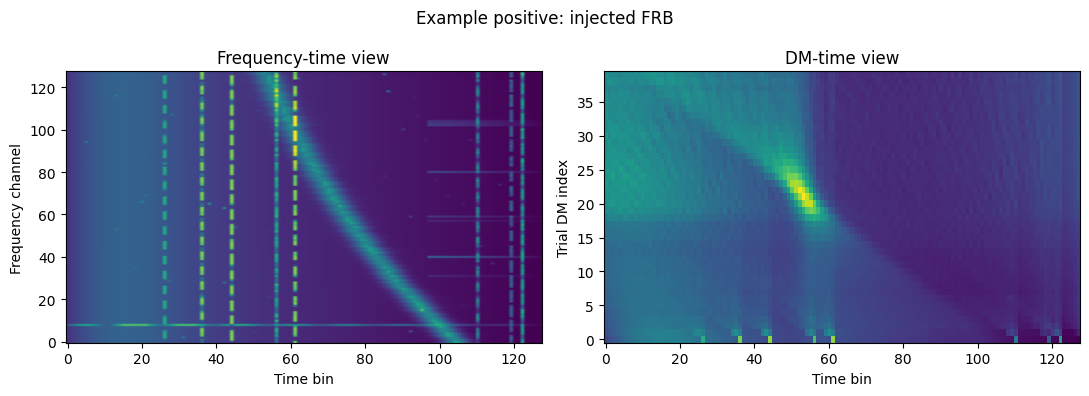

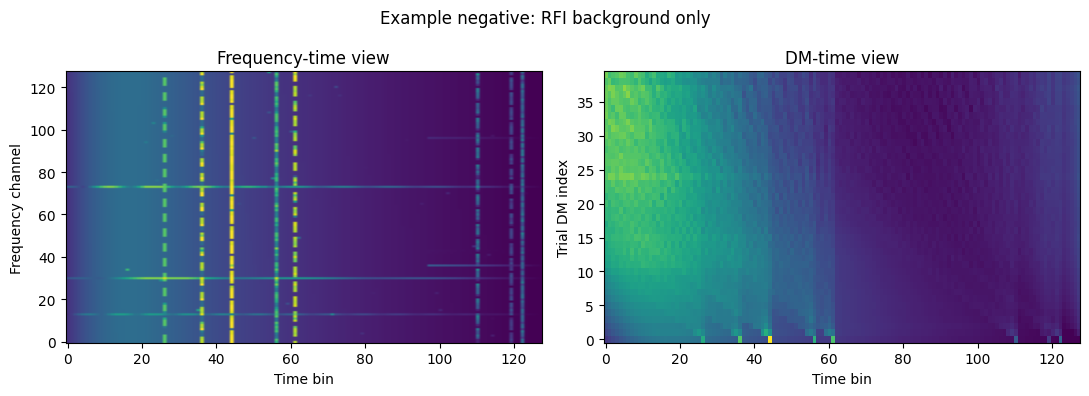

In [66]:
def plot_example(ft, dm_img, title, out_path=None):
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].imshow(ft, aspect="auto", origin="lower")
    ax[0].set_title("Frequency-time view")
    ax[0].set_xlabel("Time bin")
    ax[0].set_ylabel("Frequency channel")

    ax[1].imshow(dm_img, aspect="auto", origin="lower")
    ax[1].set_title("DM-time view")
    ax[1].set_xlabel("Time bin")
    ax[1].set_ylabel("Trial DM index")

    fig.suptitle(title)
    fig.tight_layout()
    if out_path is not None:
        fig.savefig(out_path, dpi=300, bbox_inches="tight")
    plt.show()

pos_i = int(np.where(y_test == 1)[0][0])
neg_i = int(np.where(y_test == 0)[0][0])

plot_example(test_ft[pos_i], test_dm[pos_i], "Example positive: injected FRB", FIG_DIR / "example_positive_ft_dm.png")
plot_example(test_ft[neg_i], test_dm[neg_i], "Example negative: RFI background only", FIG_DIR / "example_negative_ft_dm.png")

## 8.1. DM-time physical sanity check

Before trusting the DM-time representation, confirm that the dedispersion transform behaves physically: for several **positive** test examples (sorted by injected SNR), the trial-DM row carrying the **strongest coherent response** should sit close to the **injected DM**.

The check rebuilds a *coherent* DM-time map for each example (sum across frequency channels divided by the number of valid channels, **without** the per-image robust standardisation used for the network inputs), then takes the per-row maximum across time. The trial DM at the strongest row is the recovered DM. Because the trial-DM grid is coarse (`N_DM_TRIALS` rows spanning `DM_TRIAL_MIN`..`DM_TRIAL_MAX`), recovery is expected to land within roughly **one trial-DM step** of the injected value, not to be exact.


Trial-DM step: 30.8 pc cm^-3
Recovered within one trial step: 50% of 10 examples (median |error| = 31.3 pc cm^-3)
Saved DM-time model inputs: shape/finite-value checks PASS
 test_index  injected_dm  injected_snr  recovered_dm_from_dm_map  recovered_row  abs_error_pc_cm3  within_one_trial_step  saved_dm_shape_valid  saved_dm_finite
         39       518.21          7.88                    553.85             18             35.64                  False                  True             True
         12       306.63          7.69                    892.31             29            585.68                  False                  True             True
         73       451.36          7.62                    461.54             15             10.18                   True                  True             True
         68       365.39          7.57                    338.46             11             26.93                   True                  True             True
         83       498.32   

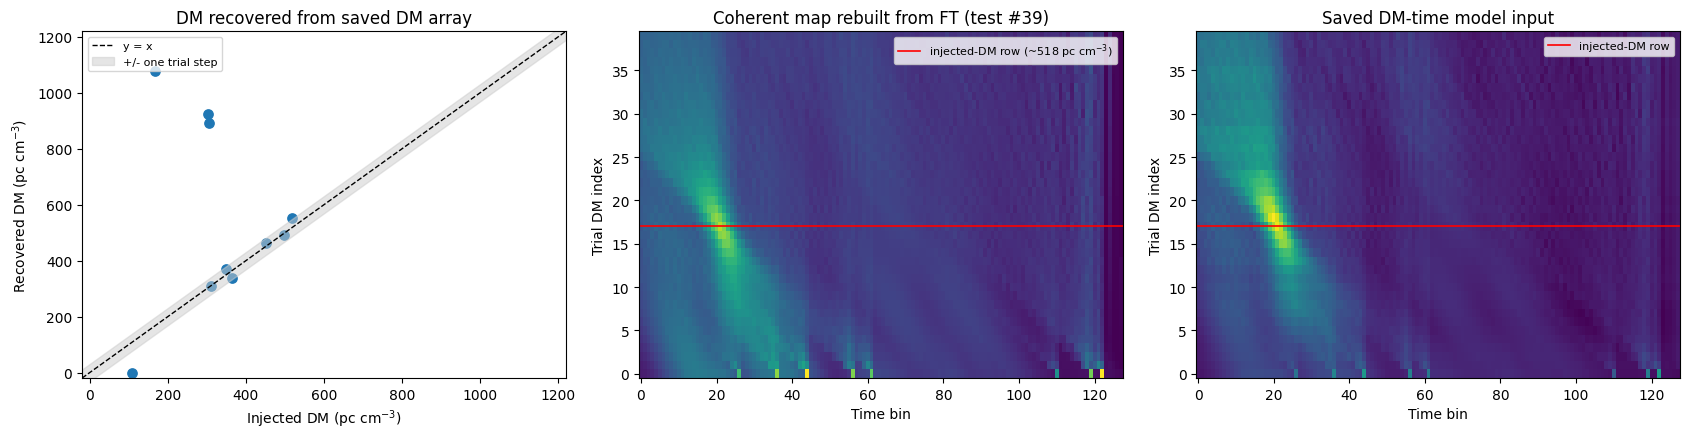

Saved dm_time_sanity_check.csv and dm_time_sanity_check.png


In [67]:
def ft_to_dm_coherent(ft, align):
    """Build a coherent DM-time map from a frequency-time image."""
    idx, valid, ch, counts = align
    ft = np.squeeze(np.asarray(ft, dtype=np.float32))

    expected_nfreq = int(np.max(ch)) + 1
    expected_ntime = int(idx.shape[-1])
    expected_shape = (expected_nfreq, expected_ntime)

    if ft.ndim != 2 or ft.shape != expected_shape:
        raise ValueError(
            f"Expected 2D FT image with shape {expected_shape}, received {ft.shape}."
        )

    aligned = ft[ch, idx].astype(np.float32)
    aligned = np.where(valid, aligned, 0.0)
    return aligned.sum(axis=1) / counts


def recovered_dm_from_ft(ft, align, trial_dms):
    """Recover DM by constructing a coherent DM-time map from an FT image."""
    dm_map = ft_to_dm_coherent(ft, align)
    row_strength = dm_map.max(axis=1)
    best_row = int(np.argmax(row_strength))
    return float(trial_dms[best_row]), best_row, dm_map


def recovered_dm_from_dm_map(dm_map, trial_dms):
    """Recover DM peak directly from an already-generated DM-time map."""
    dm_map = np.squeeze(np.asarray(dm_map, dtype=np.float32))

    expected_shape = (len(trial_dms), CONFIG["NTIME"])
    if dm_map.shape != expected_shape:
        raise ValueError(
            f"Expected DM-time shape {expected_shape}, received {dm_map.shape}."
        )

    row_strength = np.max(dm_map, axis=1)
    best_row = int(np.argmax(row_strength))

    return float(trial_dms[best_row]), best_row


def validate_saved_dm_map(dm_map, trial_dms, expected_ntime):
    """Validate the already-created DM-time model input without re-transforming it."""
    dm_map = np.squeeze(np.asarray(dm_map, dtype=np.float32))
    expected_shape = (len(trial_dms), expected_ntime)

    if dm_map.ndim != 2 or dm_map.shape != expected_shape:
        raise ValueError(
            f"Expected a saved DM-time image with shape {expected_shape}, "
            f"but received {dm_map.shape}."
        )
    if not np.isfinite(dm_map).all():
        raise ValueError("Saved DM-time model input contains NaN or infinite values.")
    if float(np.std(dm_map)) <= 1e-8:
        raise ValueError("Saved DM-time model input is effectively constant.")
    return dm_map


# Trial-DM grid spacing sets the resolution we can reasonably expect to recover.
dm_trial_step = float(DM_TRIALS[1] - DM_TRIALS[0])

# Use positive TEST examples, strongest injected SNR first.
pos_idx = np.where(y_test == 1)[0]
pos_snr = meta_test.iloc[pos_idx]["snr"].to_numpy(dtype=float)
order = pos_idx[np.argsort(-pos_snr)]
sanity_idx = order[: min(10, len(order))]

sanity_rows = []
for i in sanity_idx:
    i = int(i)
    injected_dm = float(meta_test.iloc[i]["dm"])
    injected_snr = float(meta_test.iloc[i]["snr"])

    # Recover from saved map array
    rec_dm, rec_row = recovered_dm_from_dm_map(
        test_dm[i],
        DM_TRIALS,
    )

    # Separately validate the saved DM-time array that is passed to the models.
    validate_saved_dm_map(test_dm[i], DM_TRIALS, CONFIG["NTIME"])

    abs_err = abs(injected_dm - rec_dm)
    sanity_rows.append({
        "test_index": i,
        "injected_dm": round(injected_dm, 2),
        "injected_snr": round(injected_snr, 2),
        "recovered_dm_from_dm_map": round(rec_dm, 2),
        "recovered_row": rec_row,
        "abs_error_pc_cm3": round(abs_err, 2),
        "within_one_trial_step": bool(abs_err <= dm_trial_step + 1e-6),
        "saved_dm_shape_valid": True,
        "saved_dm_finite": True,
    })


dm_sanity_df = pd.DataFrame(sanity_rows)
dm_sanity_df.to_csv(TABLE_DIR / "dm_time_sanity_check.csv", index=False)

frac_ok = (
    float(dm_sanity_df["within_one_trial_step"].mean())
    if len(dm_sanity_df)
    else float("nan")
)
median_err = (
    float(dm_sanity_df["abs_error_pc_cm3"].median())
    if len(dm_sanity_df)
    else float("nan")
)

print(f"Trial-DM step: {dm_trial_step:.1f} pc cm^-3")
print(
    f"Recovered within one trial step: {frac_ok:.0%} of {len(dm_sanity_df)} examples "
    f"(median |error| = {median_err:.1f} pc cm^-3)"
)
print("Saved DM-time model inputs: shape/finite-value checks PASS")
print(dm_sanity_df.to_string(index=False))

# Figure: injected vs recovered DM, coherent DM-time map, and saved DM model input.
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

ax[0].scatter(dm_sanity_df["injected_dm"], dm_sanity_df["recovered_dm_from_dm_map"], s=45)
lim_lo = float(min(DM_TRIALS.min(), dm_sanity_df["injected_dm"].min())) - 20
lim_hi = float(max(DM_TRIALS.max(), dm_sanity_df["injected_dm"].max())) + 20
ax[0].plot([lim_lo, lim_hi], [lim_lo, lim_hi], "k--", linewidth=1, label="y = x")
ax[0].fill_between(
    [lim_lo, lim_hi],
    [lim_lo - dm_trial_step, lim_hi - dm_trial_step],
    [lim_lo + dm_trial_step, lim_hi + dm_trial_step],
    color="0.8",
    alpha=0.5,
    label="+/- one trial step",
)
ax[0].set_xlim(lim_lo, lim_hi)
ax[0].set_ylim(lim_lo, lim_hi)
ax[0].set_xlabel("Injected DM (pc cm$^{-3}$)")
ax[0].set_ylabel("Recovered DM (pc cm$^{-3}$)")
ax[0].set_title("DM recovered from saved DM array")
ax[0].legend(fontsize=8)

ex_i = int(sanity_idx[0])
ex_inj_dm = float(meta_test.iloc[ex_i]["dm"])

# Rebuilt coherent map from FT using recovered_dm_from_ft
_, _, ex_map = recovered_dm_from_ft(test_ft[ex_i], DM_ALIGN, DM_TRIALS)

ex_row = int(np.argmin(np.abs(DM_TRIALS - ex_inj_dm)))

ax[1].imshow(ex_map, aspect="auto", origin="lower")
ax[1].axhline(
    ex_row,
    color="red",
    linewidth=1.2,
    label=f"injected-DM row (~{ex_inj_dm:.0f} pc cm$^{{-3}}$)",
)
ax[1].set_xlabel("Time bin")
ax[1].set_ylabel("Trial DM index")
ax[1].set_title(f"Coherent map rebuilt from FT (test #{ex_i})")
ax[1].legend(fontsize=8, loc="upper right")

saved_map = validate_saved_dm_map(test_dm[ex_i], DM_TRIALS, CONFIG["NTIME"])
ax[2].imshow(saved_map, aspect="auto", origin="lower")
ax[2].axhline(
    ex_row,
    color="red",
    linewidth=1.2,
    label="injected-DM row",
)
ax[2].set_xlabel("Time bin")
ax[2].set_ylabel("Trial DM index")
ax[2].set_title("Saved DM-time model input")
ax[2].legend(fontsize=8, loc="upper right")

fig.tight_layout()
fig.savefig(FIG_DIR / "dm_time_sanity_check.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved dm_time_sanity_check.csv and dm_time_sanity_check.png")


## 9. Target versus measured SNR

This cell plots the target injected SNR against the SNR measured in the injected image, to show how the nominal SNR label relates to the signal actually present.

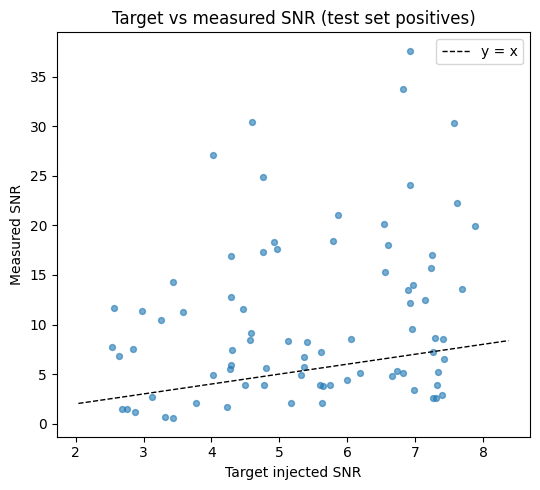

Correlation between target and measured SNR: 0.254
Saved target_vs_measured_snr.png


In [68]:
pos_meta = meta_test[meta_test["label"] == 1]
if "measured_snr" in pos_meta.columns:
    plt.figure(figsize=(5.5, 5))
    plt.scatter(pos_meta["snr"], pos_meta["measured_snr"], s=18, alpha=0.6)
    lims = [pos_meta["snr"].min() - 0.5, pos_meta["snr"].max() + 0.5]
    plt.plot(lims, lims, "k--", linewidth=1, label="y = x")
    plt.xlabel("Target injected SNR")
    plt.ylabel("Measured SNR")
    plt.title("Target vs measured SNR (test set positives)")
    plt.legend()
    plt.tight_layout()
    plt.savefig(FIG_DIR / "target_vs_measured_snr.png", dpi=300, bbox_inches="tight")
    plt.show()
    corr = pos_meta[["snr", "measured_snr"]].corr().iloc[0, 1]
    print(f"Correlation between target and measured SNR: {corr:.3f}")
    print("Saved target_vs_measured_snr.png")
else:
    print("measured_snr column not found — add it in Cell 12's injection loop first.")

## 10. Feature extraction for the baseline models

The baseline classifiers use pooled block statistics extracted from each image (the CNNs use the images directly). Features are computed for three inputs: frequency-time only, DM-time only, and the two combined (dual).

In [69]:
def safe_skew_and_kurtosis(x):
    x = np.asarray(x, dtype=np.float32).ravel()
    mu = float(np.mean(x))
    sd = float(np.std(x) + 1e-6)
    z = (x - mu) / sd
    skew = float(np.mean(z**3))
    kurt = float(np.mean(z**4) - 3.0)
    return skew, kurt


def pooled_features(img, n_rows, n_cols):
    """Extract pooled statistics over a fixed grid plus global image statistics."""
    img = np.asarray(img, dtype=np.float32)
    H, W = img.shape
    feats = []

    for r in range(n_rows):
        r0 = round(r * H / n_rows)
        r1 = round((r + 1) * H / n_rows)
        for c in range(n_cols):
            c0 = round(c * W / n_cols)
            c1 = round((c + 1) * W / n_cols)
            block = img[r0:r1, c0:c1]
            feats.extend([
                float(np.mean(block)),
                float(np.std(block)),
                float(np.max(block)),
            ])

    flat = img.ravel()
    skew, kurt = safe_skew_and_kurtosis(flat)
    feats.extend([
        float(np.mean(flat)),
        float(np.std(flat)),
        float(np.percentile(flat, 90)),
        float(np.percentile(flat, 95)),
        float(np.percentile(flat, 99)),
        float(np.max(flat)),
        skew,
        kurt,
    ])

    return np.array(feats, dtype=np.float32)


def build_feature_matrices(X_ft, X_dm):
    F_ft = np.vstack([pooled_features(x, n_rows=8, n_cols=8) for x in X_ft])
    F_dm = np.vstack([pooled_features(x, n_rows=5, n_cols=8) for x in X_dm])
    F_dual = np.hstack([F_ft, F_dm])
    return F_ft, F_dm, F_dual

train_F_ft, train_F_dm, train_F_dual = build_feature_matrices(train_ft, train_dm)
val_F_ft, val_F_dm, val_F_dual = build_feature_matrices(val_ft, val_dm)
test_F_ft, test_F_dm, test_F_dual = build_feature_matrices(test_ft, test_dm)

print("FT features:", train_F_ft.shape)
print("DM features:", train_F_dm.shape)
print("Dual features:", train_F_dual.shape)

#Add the channel dimension for the CNNs
def add_channel(X):
    return X[..., None].astype(np.float32)

train_ft_cnn, val_ft_cnn, test_ft_cnn = add_channel(train_ft), add_channel(val_ft), add_channel(test_ft)
train_dm_cnn, val_dm_cnn, test_dm_cnn = add_channel(train_dm), add_channel(val_dm), add_channel(test_dm)

FT features: (320, 200)
DM features: (320, 128)
Dual features: (320, 328)


## 11. Keras-to-scikit-learn wrapper

This cell defines `KerasClassifierWrapper`, an adapter that gives Keras models a scikit-learn-style interface. Keras returns a single probability column for binary classification and handles validation data differently, so the wrapper returns two-column probabilities (`[prob_negative, prob_positive]`) and applies early stopping and history saving. This allows the CNNs and the classical baselines to be evaluated and plotted in the same loop.

In [70]:
class KerasClassifierWrapper:
    """Wraps a Keras model to mimic Scikit-Learn's API, with early stopping and saved history."""
    def __init__(self, keras_model, epochs=35, batch_size=32, patience=7):
        self.model = keras_model
        self.epochs = epochs
        self.batch_size = batch_size
        self.patience = patience
        self.history = None
        self.history_df = None

    def fit(self, X, y, validation_data=None):
        callbacks = []
        if validation_data is not None:
            # Stop when validation PR-AUC stops improving and restore the best weights.
            callbacks.append(
                keras.callbacks.EarlyStopping(
                    monitor="val_pr_auc",
                    mode="max",
                    patience=self.patience,
                    restore_best_weights=True,
                    verbose=0,
                )
            )
        self.history = self.model.fit(
            X, y,
            epochs=self.epochs,
            batch_size=self.batch_size,
            validation_data=validation_data,
            callbacks=callbacks,
            verbose=0,
        )
        self.history_df = pd.DataFrame(self.history.history)
        return self

    def predict_proba(self, X):
        preds = self.model.predict(X, verbose=0).ravel()
        return np.vstack([1 - preds, preds]).T


## 12. CNN model definitions

This section defines the three CNNs with the Keras functional API.

**Shared building blocks.** `conv_block` applies `Conv2D -> BatchNormalization -> ReLU`, then an optional `MaxPooling2D` and `Dropout`. `pooled_head` concatenates global average and global max pooling so that a localised DM-time peak is not diluted. `classification_head` adds a small dense head (`Dropout -> Dense(64) -> Dropout -> Dense(1, sigmoid)`). Every model is compiled with Adam and binary cross-entropy and tracks accuracy, ROC-AUC and PR-AUC; early stopping monitors validation PR-AUC.

1. `build_single_input_cnn`: a four-block network (16, 32, 64 and 128 filters, dropout of 0.15 to 0.30, and no pooling in block 4) for a single representation.
   - The **FT CNN** (128 x 128 input) uses symmetric `(2, 2)` pooling in blocks 1-3.
   - The **DM CNN** is adapted to the DM-time geometry. The DM-time image is only `N_DM x NTIME` (40 x 128), so repeated symmetric pooling would collapse the narrow DM axis. It therefore uses anisotropic `(1, 2)` pooling in the first two blocks, followed by `(2, 2)` in block 3.

2. `build_dual_input_cnn`: two parallel four-block encoders, one per representation, each pooled and projected to a 64-unit vector, then concatenated before the shared classification head. The FT branch uses symmetric pooling, and the DM branch uses the same anisotropic pooling as the standalone DM CNN.

In [71]:
def conv_block(x, filters, pool_size=(2, 2), dropout=0.15, name_prefix=None):
    """Conv2D -> BatchNorm -> ReLU, then optional MaxPooling and Dropout."""
    nm = (lambda s: None) if name_prefix is None else (lambda s: f"{name_prefix}_{s}")
    x = layers.Conv2D(filters, 3, padding="same", name=nm("conv"))(x)
    x = layers.BatchNormalization(name=nm("bn"))(x)
    x = layers.Activation("relu", name=nm("relu"))(x)
    if pool_size is not None:
        x = layers.MaxPooling2D(pool_size=pool_size, name=nm("pool"))(x)
    if dropout and dropout > 0:
        x = layers.Dropout(dropout, name=nm("drop"))(x)
    return x


def pooled_head(x):
    """Concatenated global average + max pooling so localized DM-time peaks are not diluted."""
    a = layers.GlobalAveragePooling2D()(x)
    m = layers.GlobalMaxPooling2D()(x)
    return layers.Concatenate()([a, m])


def classification_head(x):
    """Shared dense classification head."""
    x = layers.Dropout(0.35)(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(0.25)(x)
    return layers.Dense(1, activation="sigmoid")(x)


def compile_binary_model(model):
    """Compile with Adam + BCE and track both ROC-AUC and PR-AUC (PR-AUC drives early stopping)."""
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=CONFIG["CNN_LEARNING_RATE"]),
        loss="binary_crossentropy",
        metrics=[
            "accuracy",
            keras.metrics.AUC(name="roc_auc"),
            keras.metrics.AUC(curve="PR", name="pr_auc"),
        ],
    )
    return model

#4-block single-input architecture for FT and DM CNN
def build_single_input_cnn(input_shape, name, pool_sizes=None):
    """4-block single-input CNN.

    pool_sizes: list of 3 pool sizes for blocks 1-3 (block 4 has no pooling).
                Defaults to symmetric (2, 2) pooling (used by the FT CNN).
                The DM CNN passes [(1, 2), (1, 2), (2, 2)] so the narrow 40-pixel DM
                axis is preserved through the first two blocks instead of being crushed.
    """
    if pool_sizes is None:
        pool_sizes = [(2, 2), (2, 2), (2, 2)]

    inputs = keras.Input(shape=input_shape)
    x = conv_block(inputs, 16, pool_sizes[0], 0.15, name_prefix=f"{name}_b1")
    x = conv_block(x, 32, pool_sizes[1], 0.20, name_prefix=f"{name}_b2")
    x = conv_block(x, 64, pool_sizes[2], 0.25, name_prefix=f"{name}_b3")
    x = conv_block(x, 128, None, 0.30, name_prefix=f"{name}_b4")
    x = pooled_head(x)
    outputs = classification_head(x)
    return compile_binary_model(keras.Model(inputs, outputs, name=name))


#4-block Dual CNN architecture
def build_dual_input_cnn(shape_ft, shape_dm, name="Dual_CNN"):
    """Dual-input CNN with symmetric 4-block encoders and 64-D projection heads."""
    inp_ft = keras.Input(shape=shape_ft, name="ft_input")
    inp_dm = keras.Input(shape=shape_dm, name="dm_input")

    def branch(inp, pools, prefix):
        x = conv_block(inp, 16, pools[0], 0.15, name_prefix=f"{prefix}_b1")
        x = conv_block(x, 32, pools[1], 0.20, name_prefix=f"{prefix}_b2")
        x = conv_block(x, 64, pools[2], 0.25, name_prefix=f"{prefix}_b3")
        x = conv_block(x, 128, None, 0.30, name_prefix=f"{prefix}_b4")
        x = pooled_head(x)
        x = layers.Dense(64, activation="relu", name=f"{prefix}_projection")(x)
        x = layers.BatchNormalization(name=f"{prefix}_projection_bn")(x)
        return x

    branch_ft = branch(inp_ft, [(2, 2), (2, 2), (2, 2)], "dual_ft")
    branch_dm = branch(inp_dm, [(1, 2), (1, 2), (2, 2)], "dual_dm")

    merged = layers.Concatenate()([branch_ft, branch_dm])
    outputs = classification_head(merged)
    return compile_binary_model(keras.Model([inp_ft, inp_dm], outputs, name=name))


# Print a compact summary of each architecture so the paper can report it accurately.
_demo_ft = build_single_input_cnn((CONFIG["NFREQ"], CONFIG["NTIME"], 1), "FT_CNN_preview")
_demo_dm = build_single_input_cnn((CONFIG["N_DM_TRIALS"], CONFIG["NTIME"], 1), "DM_CNN_preview",
                                  pool_sizes=[(1, 2), (1, 2), (2, 2)])
_demo_dual = build_dual_input_cnn((CONFIG["NFREQ"], CONFIG["NTIME"], 1),
                                  (CONFIG["N_DM_TRIALS"], CONFIG["NTIME"], 1), "Dual_CNN_preview")
print("FT CNN   trainable params:", f"{_demo_ft.count_params():,}")
print("DM CNN   trainable params:", f"{_demo_dm.count_params():,}", "(anisotropic pooling + avg/max)")
print("Dual CNN trainable params:", f"{_demo_dual.count_params():,}")


FT CNN   trainable params: 114,625
DM CNN   trainable params: 114,625 (anisotropic pooling + avg/max)
Dual CNN trainable params: 237,953


## 12.1. Model Summaries

This cell reports the exact architectures of each model defined in the above cell.

In [72]:
print("=" * 70)
print("FT CNN architecture")
print("=" * 70)
_demo_ft.summary()

print("\n" + "=" * 70)
print("DM CNN architecture")
print("=" * 70)
_demo_dm.summary()

print("\n" + "=" * 70)
print("Dual CNN architecture")
print("=" * 70)
_demo_dual.summary()

# Save each summary to a text file.
for _model, _name in [(_demo_ft, "ft_cnn"), (_demo_dm, "dm_cnn"), (_demo_dual, "dual_cnn")]:
    lines = []
    _model.summary(print_fn=lambda s: lines.append(s))
    with open(TEXT_DIR / f"model_summary_{_name}.txt", "w", encoding="utf-8") as f:
        f.write("\n".join(lines))

print("\nSaved model_summary_ft_cnn.txt, model_summary_dm_cnn.txt, model_summary_dual_cnn.txt")

FT CNN architecture


Model: "FT_CNN_preview"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_16      │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ FT_CNN_preview_b1_… │ (None, 128, 128,  │        160 │ input_layer_16[0… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ FT_CNN_preview_b1_… │ (None, 128, 128,  │         64 │ FT_CNN_preview_b… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ FT_CNN_preview_b1_… │ (None, 128, 128,  │          0 │ FT_CNN_preview_b… │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ FT_CNN_preview_b1_… │ (None, 64, 64,    │          0 │ FT_CNN_preview_b… │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ FT_CNN_preview_b1_… │ (None, 64, 64,    │          0 │ FT_CNN_preview_b… │
│ (Dropout)           │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ FT_CNN_preview_b2_… │ (None, 64, 64,    │      4,640 │ FT_CNN_preview_b… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ FT_CNN_preview_b2_… │ (None, 64, 64,    │        128 │ FT_CNN_preview_b… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ FT_CNN_preview_b2_… │ (None, 64, 64,    │          0 │ FT_CNN_preview_b… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ FT_CNN_preview_b2_… │ (None, 32, 32,    │          0 │ FT_CNN_preview_b… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ FT_CNN_preview_b2_… │ (None, 32, 32,    │          0 │ FT_CNN_preview_b… │
│ (Dropout)           │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ FT_CNN_preview_b3_… │ (None, 32, 32,    │     18,496 │ FT_CNN_preview_b… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ FT_CNN_preview_b3_… │ (None, 32, 32,    │        256 │ FT_CNN_preview_b… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ FT_CNN_preview_b3_… │ (None, 32, 32,    │          0 │ FT_CNN_preview_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ FT_CNN_preview_b3_… │ (None, 16, 16,    │          0 │ FT_CNN_preview_b… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ FT_CNN_preview_b3_… │ (None, 16, 16,    │          0 │ FT_CNN_preview_b… │
│ (Dropout)           │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ FT_CNN_preview_b4_… │ (None, 16, 16,    │     73,856 │ FT_CNN_preview_b

 Total params: 114,625 (447.75 KB)

 Trainable params: 114,145 (445.88 KB)

...

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ ft_input            │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dm_input            │ (None, 40, 128,   │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dual_ft_b1_conv     │ (None, 128, 128,  │        160 │ ft_input[0][0]    │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dual_dm_b1_conv     │ (None, 40, 128,   │        160 │ dm_input[0][0]    │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dual_ft_b1_bn       │ (None, 128, 128,  │         64 │ dual_ft_b1_conv[… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dual_dm_b1_bn       │ (None, 40, 128,   │         64 │ dual_dm_b1_conv[… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dual_ft_b1_relu     │ (None, 128, 128,  │          0 │ dual_ft_b1_bn[0]… │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dual_dm_b1_relu     │ (None, 40, 128,   │          0 │ dual_dm_b1_bn[0]… │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dual_ft_b1_pool     │ (None, 64, 64,    │          0 │ dual_ft_b1_relu[… │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dual_dm_b1_pool     │ (None, 40, 64,    │          0 │ dual_dm_b1_relu[… │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dual_ft_b1_drop     │ (None, 64, 64,    │          0 │ dual_ft_b1_pool[… │
│ (Dropout)           │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dual_dm_b1_drop     │ (None, 40, 64,    │          0 │ dual_dm_b1_pool[… │
│ (Dropout)           │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dual_ft_b2_conv     │ (None, 64, 64,    │      4,640 │ dual_ft_b1_drop[… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dual_dm_b2_conv     │ (None, 40, 64,    │      4,640 │ dual_dm_b1_drop[… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dual_ft_b2_bn       │ (None, 64, 64,    │        128 │ dual_ft_b2_conv[… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dual_dm_b2_bn       │ (None, 40, 64,    │        128 │ dual_dm_b2_conv[… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dual_ft_b2_relu     │ (None, 64, 64,    │          0 │ dual_ft_b2_bn[0]

 Total params: 237,953 (929.50 KB)

 Trainable params: 236,737 (924.75 KB)

 Non-trainable params: 1,216 (4.75 KB)


Saved model_summary_ft_cnn.txt, model_summary_dm_cnn.txt, model_summary_dual_cnn.txt


## 13. Train models (baselines once, CNNs across seeds with early stopping)

The baseline models (logistic regression, random forest, extra trees and XGBoost on FT, DM and dual features) are deterministic given their `random_state`, so they are trained once.

The three CNNs (FT, DM, Dual) are trained once **per seed** in `CONFIG["SEED_LIST"]`, each with **early stopping** on validation PR-AUC (`restore_best_weights=True`). The **dataset split is held fixed**, so the spread across seeds reflects CNN **training stochasticity** (weight initialisation, dropout sampling and mini-batch order), not data resampling. The first seed populates the canonical `trained` / `test_probs` used by the plots and saves its per-epoch training history; all seeds feed the mean +/- standard deviation table in the next section.

In [73]:
shape_ft = train_ft_cnn.shape[1:]
shape_dm = train_dm_cnn.shape[1:]

# ----------------------------------------------------------------------
# Baseline (non-CNN) models and the features they use.
# ----------------------------------------------------------------------
BASELINE_FEATURES = {
    "FT logistic": (train_F_ft, val_F_ft, test_F_ft),
    "DM logistic": (train_F_dm, val_F_dm, test_F_dm),
    "Dual logistic": (train_F_dual, val_F_dual, test_F_dual),
    "FT random forest": (train_F_ft, val_F_ft, test_F_ft),
    "DM random forest": (train_F_dm, val_F_dm, test_F_dm),
    "Dual random forest": (train_F_dual, val_F_dual, test_F_dual),
    "Dual extra trees": (train_F_dual, val_F_dual, test_F_dual),
    "FT XGBoost": (train_F_ft, val_F_ft, test_F_ft),
    "DM XGBoost": (train_F_dm, val_F_dm, test_F_dm),
    "Dual XGBoost": (train_F_dual, val_F_dual, test_F_dual),
}


def make_baseline_models():
    return {
        "FT logistic": make_pipeline(
            StandardScaler(),
            LogisticRegression(max_iter=1500, class_weight="balanced", random_state=SEED),
        ),
        "DM logistic": make_pipeline(
            StandardScaler(),
            LogisticRegression(max_iter=1500, class_weight="balanced", random_state=SEED),
        ),
        "Dual logistic": make_pipeline(
            StandardScaler(),
            LogisticRegression(max_iter=1500, class_weight="balanced", random_state=SEED),
        ),
        "FT random forest": RandomForestClassifier(
            n_estimators=CONFIG["RANDOM_FOREST_TREES"], max_depth=CONFIG["RANDOM_FOREST_MAX_DEPTH"],
            min_samples_leaf=2, class_weight="balanced", random_state=SEED, n_jobs=-1,
        ),
        "DM random forest": RandomForestClassifier(
            n_estimators=CONFIG["RANDOM_FOREST_TREES"], max_depth=CONFIG["RANDOM_FOREST_MAX_DEPTH"],
            min_samples_leaf=2, class_weight="balanced", random_state=SEED, n_jobs=-1,
        ),
        "Dual random forest": RandomForestClassifier(
            n_estimators=CONFIG["RANDOM_FOREST_TREES"], max_depth=CONFIG["RANDOM_FOREST_MAX_DEPTH"],
            min_samples_leaf=2, class_weight="balanced", random_state=SEED, n_jobs=-1,
        ),
        "Dual extra trees": ExtraTreesClassifier(
            n_estimators=CONFIG["RANDOM_FOREST_TREES"], max_depth=CONFIG["RANDOM_FOREST_MAX_DEPTH"],
            min_samples_leaf=2, class_weight="balanced", random_state=SEED, n_jobs=-1,
        ),
        "FT XGBoost": XGBClassifier(
            n_estimators=CONFIG["XGB_ESTIMATORS"], max_depth=CONFIG["XGB_MAX_DEPTH"],
            learning_rate=CONFIG["XGB_LEARNING_RATE"], random_state=SEED, eval_metric="logloss", n_jobs=-1,
        ),
        "DM XGBoost": XGBClassifier(
            n_estimators=CONFIG["XGB_ESTIMATORS"], max_depth=CONFIG["XGB_MAX_DEPTH"],
            learning_rate=CONFIG["XGB_LEARNING_RATE"], random_state=SEED, eval_metric="logloss", n_jobs=-1,
        ),
        "Dual XGBoost": XGBClassifier(
            n_estimators=CONFIG["XGB_ESTIMATORS"], max_depth=CONFIG["XGB_MAX_DEPTH"],
            learning_rate=CONFIG["XGB_LEARNING_RATE"], random_state=SEED, eval_metric="logloss", n_jobs=-1,
        ),
    }


trained = {}
val_probs = {}
test_probs = {}

# Train baselines once (deterministic given random_state).
set_all_seeds(SEED)
for name, model in make_baseline_models().items():
    Xtr, Xv, Xt = BASELINE_FEATURES[name]
    model.fit(Xtr, y_train)
    trained[name] = model
    val_probs[name] = model.predict_proba(Xv)[:, 1]
    test_probs[name] = model.predict_proba(Xt)[:, 1]
    print(f"Trained {name}")

# ----------------------------------------------------------------------
# CNNs: one fresh model per seed, with early stopping on val PR-AUC.
# ----------------------------------------------------------------------
CNN_FEATURES = {
    "FT CNN": (train_ft_cnn, val_ft_cnn, test_ft_cnn),
    "DM CNN": (train_dm_cnn, val_dm_cnn, test_dm_cnn),
    "Dual CNN": ([train_ft_cnn, train_dm_cnn], [val_ft_cnn, val_dm_cnn], [test_ft_cnn, test_dm_cnn]),
}
CNN_NAMES = ["FT CNN", "DM CNN", "Dual CNN"]

def build_cnn(name):
    if name == "FT CNN":
        return build_single_input_cnn(shape_ft, "FT_CNN")
    if name == "DM CNN":
        return build_single_input_cnn(shape_dm, "DM_CNN", pool_sizes=[(1, 2), (1, 2), (2, 2)])
    if name == "Dual CNN":
        return build_dual_input_cnn(shape_ft, shape_dm, "Dual_CNN")
    raise ValueError(name)

SEED_LIST = CONFIG["SEED_LIST"]
cnn_seed_probs = {}
cnn_histories = {}
cnn_seed_histories = {name: {} for name in CNN_NAMES}

print(f"\nTraining CNNs across {len(SEED_LIST)} seed(s): {SEED_LIST}")
for si, seed in enumerate(SEED_LIST):
    set_all_seeds(seed)
    cnn_seed_probs[seed] = {}
    for name in CNN_NAMES:
        Xtr, Xv, Xt = CNN_FEATURES[name]
        wrapper = KerasClassifierWrapper(
            build_cnn(name),
            epochs=CONFIG["CNN_EPOCHS"],
            batch_size=CONFIG["CNN_BATCH_SIZE"],
            patience=CONFIG["CNN_EARLY_STOP_PATIENCE"],
        )
        wrapper.fit(Xtr, y_train, validation_data=(Xv, y_val))
        vp = wrapper.predict_proba(Xv)[:, 1]
        tp = wrapper.predict_proba(Xt)[:, 1]
        cnn_seed_probs[seed][name] = {"val": vp, "test": tp}

        cnn_seed_histories[name][seed] = dict(wrapper.history.history)

        if si == 0:
            trained[name] = wrapper
            val_probs[name] = vp
            test_probs[name] = tp
            cnn_histories[name] = dict(wrapper.history.history)
            safe = name.lower().replace(" ", "_")
            wrapper.history_df.to_csv(TABLE_DIR / f"training_history_{safe}.csv", index=False)
        print(f"  seed {seed}: trained {name} ({len(wrapper.history_df)} epochs after early stopping)")

print(f"\nDone. Trained {len(BASELINE_FEATURES)} baselines and {len(CNN_NAMES)} CNNs x {len(SEED_LIST)} seed(s).")


Trained FT logistic
Trained DM logistic
Trained Dual logistic
Trained FT random forest
Trained DM random forest
Trained Dual random forest
Trained Dual extra trees
Trained FT XGBoost
Trained DM XGBoost
Trained Dual XGBoost

Training CNNs across 3 seed(s): [123, 7, 2024]
  seed 123: trained FT CNN (35 epochs after early stopping)
  seed 123: trained DM CNN (35 epochs after early stopping)
  seed 123: trained Dual CNN (31 epochs after early stopping)
  seed 7: trained FT CNN (17 epochs after early stopping)
  seed 7: trained DM CNN (24 epochs after early stopping)
  seed 7: trained Dual CNN (31 epochs after early stopping)
  seed 2024: trained FT CNN (35 epochs after early stopping)
  seed 2024: trained DM CNN (26 epochs after early stopping)
  seed 2024: trained Dual CNN (32 epochs after early stopping)

Done. Trained 10 baselines and 3 CNNs x 3 seed(s).


## 14. Evaluation metrics

The decision threshold is selected on the validation set using Youden's statistic, then held fixed for the test set.

This avoids tuning the threshold on the test set.

In [74]:
def choose_threshold_from_validation(y_true, p):
    fpr, tpr, thresholds = roc_curve(y_true, p)
    j = tpr - fpr
    return float(thresholds[int(np.argmax(j))])


def evaluate_probabilities(name, y_val, p_val, y_test, p_test):
    threshold = choose_threshold_from_validation(y_val, p_val)
    y_pred = (p_test >= threshold).astype(int)

    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test, y_pred, average="binary", zero_division=0
    )
    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()

    return {
        "model": name,
        "model_family": "CNN" if "CNN" in name else "baseline",
        "threshold_from_val": threshold,
        "accuracy": float(accuracy_score(y_test, y_pred)),
        "precision": float(precision),
        "recall": float(recall),
        "f1": float(f1),
        "roc_auc": float(roc_auc_score(y_test, p_test)),
        "pr_auc": float(average_precision_score(y_test, p_test)),
        "false_positive_rate": float(fp / max(fp + tn, 1)),
        "true_negative": int(tn),
        "false_positive": int(fp),
        "false_negative": int(fn),
        "true_positive": int(tp),
    }


# Main results table: all models, using the first-seed probabilities for the CNNs.
results = []
for name in trained:
    results.append(evaluate_probabilities(name, y_val, val_probs[name], y_test, test_probs[name]))

results_df = pd.DataFrame(results).sort_values("pr_auc", ascending=False).reset_index(drop=True)

# Split into the CNN comparison (the paper's main table) and the baseline diagnostics.
CNN_NAMES_EVAL = ["FT CNN", "DM CNN", "Dual CNN"]
cnn_results_df = (
    results_df[results_df["model"].isin(CNN_NAMES_EVAL)]
    .sort_values("pr_auc", ascending=False).reset_index(drop=True)
)
baseline_results_df = (
    results_df[~results_df["model"].isin(CNN_NAMES_EVAL)]
    .sort_values("pr_auc", ascending=False).reset_index(drop=True)
)

results_df.to_csv(TABLE_DIR / "model_results_all_models.csv", index=False)
cnn_results_df.to_csv(TABLE_DIR / "model_results_cnn_main_table.csv", index=False)
baseline_results_df.to_csv(TABLE_DIR / "model_results_baseline_secondary_table.csv", index=False)

# ----------------------------------------------------------------------
# CNN reproducibility: metrics for every seed, then mean +/- std per CNN.
# ----------------------------------------------------------------------
cnn_rows = []
for seed, per in cnn_seed_probs.items():
    for name, pr in per.items():
        r = evaluate_probabilities(name, y_val, pr["val"], y_test, pr["test"])
        r["seed"] = seed
        cnn_rows.append(r)

cnn_seed_metrics_df = pd.DataFrame(cnn_rows)
cnn_seed_metrics_df.to_csv(TABLE_DIR / "cnn_seed_metrics.csv", index=False)

_metric_cols = ["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]
cnn_summary_df = (
    cnn_seed_metrics_df.groupby("model")[_metric_cols].agg(["mean", "std"]).round(4)
)
cnn_summary_df.to_csv(TABLE_DIR / "cnn_metric_summary.csv")

n_seeds = cnn_seed_metrics_df["seed"].nunique()
print(f"CNN metrics across {n_seeds} seed(s) (mean +/- std):\n")
for name in CNN_NAMES_EVAL:
    sub = cnn_seed_metrics_df[cnn_seed_metrics_df["model"] == name]
    parts = []
    for c in _metric_cols:
        sd = sub[c].std()
        sd = 0.0 if pd.isna(sd) else sd
        parts.append(f"{c}={sub[c].mean():.3f}+/-{sd:.3f}")
    print(f"  {name}: " + ", ".join(parts))

print("\nSaved: model_results_all_models.csv, model_results_cnn_main_table.csv,")
print("       model_results_baseline_secondary_table.csv, cnn_seed_metrics.csv, cnn_metric_summary.csv")
print("\nCNN main comparison table:")
cnn_results_df


CNN metrics across 3 seed(s) (mean +/- std):

  FT CNN: accuracy=0.833+/-0.224, precision=0.830+/-0.250, recall=0.958+/-0.019, f1=0.873+/-0.153, roc_auc=0.888+/-0.189, pr_auc=0.879+/-0.205
  DM CNN: accuracy=0.987+/-0.011, precision=1.000+/-0.000, recall=0.975+/-0.022, f1=0.987+/-0.011, roc_auc=0.999+/-0.001, pr_auc=0.999+/-0.001
  Dual CNN: accuracy=0.975+/-0.013, precision=1.000+/-0.000, recall=0.950+/-0.025, f1=0.974+/-0.013, roc_auc=1.000+/-0.000, pr_auc=1.000+/-0.000

Saved: model_results_all_models.csv, model_results_cnn_main_table.csv,
       model_results_baseline_secondary_table.csv, cnn_seed_metrics.csv, cnn_metric_summary.csv

CNN main comparison table:


,model,model_family,threshold_from_val,accuracy,precision,recall,f1,roc_auc,pr_auc,false_positive_rate,true_negative,false_positive,false_negative,true_positive
0,DM CNN,CNN,0.882932,1.00000,1.000000,1.0000,1.000000,1.000000,1.000000,0.000,80,0,0,80
1,Dual CNN,CNN,0.990049,0.96250,1.000000,0.9250,0.961039,1.000000,1.000000,0.000,80,0,6,74
2,FT CNN,CNN,0.442480,0.96875,0.974684,0.9625,0.968553,0.998125,0.998112,0.025,78,2,3,77


## 14.1. Per-seed summary

This cell prints the CNN metrics for each seed, together with the mean and standard deviation across seeds, to show how consistent performance is between seeds.

In [75]:
cnn_seed_metrics_df = pd.read_csv(TABLE_DIR / "cnn_seed_metrics.csv")
cnn_summary_df = pd.read_csv(TABLE_DIR / "cnn_metric_summary.csv", header=[0, 1], index_col=0)

print(cnn_seed_metrics_df[cnn_seed_metrics_df["model"].isin(["FT CNN", "DM CNN", "Dual CNN"])]
      .sort_values(["model", "seed"]).to_string(index=False))
print()
print(cnn_summary_df[[c for c in cnn_summary_df.columns if c[0] in
                       ["roc_auc", "pr_auc", "recall", "f1"]]])

   model model_family  threshold_from_val  accuracy  precision  recall       f1  roc_auc   pr_auc  false_positive_rate  true_negative  false_positive  false_negative  true_positive  seed
  DM CNN          CNN            0.486813   0.98125   1.000000  0.9625 0.980892 0.997812 0.997966                0.000             80               0               3             77     7
  DM CNN          CNN            0.882932   1.00000   1.000000  1.0000 1.000000 1.000000 1.000000                0.000             80               0               0             80   123
  DM CNN          CNN            0.533565   0.98125   1.000000  0.9625 0.980892 1.000000 1.000000                0.000             80               0               3             77  2024
Dual CNN          CNN            0.989605   0.97500   1.000000  0.9500 0.974359 1.000000 1.000000                0.000             80               0               4             76     7
Dual CNN          CNN            0.990049   0.96250   1.000000  0

## 15. CNN training curves

Accuracy, loss and AUC versus epoch for each CNN (from the first seed). These curves are used to diagnose whether a model is **underfitting** (training and validation both poor), **overfitting** (training improves while validation degrades), or **unstable**.

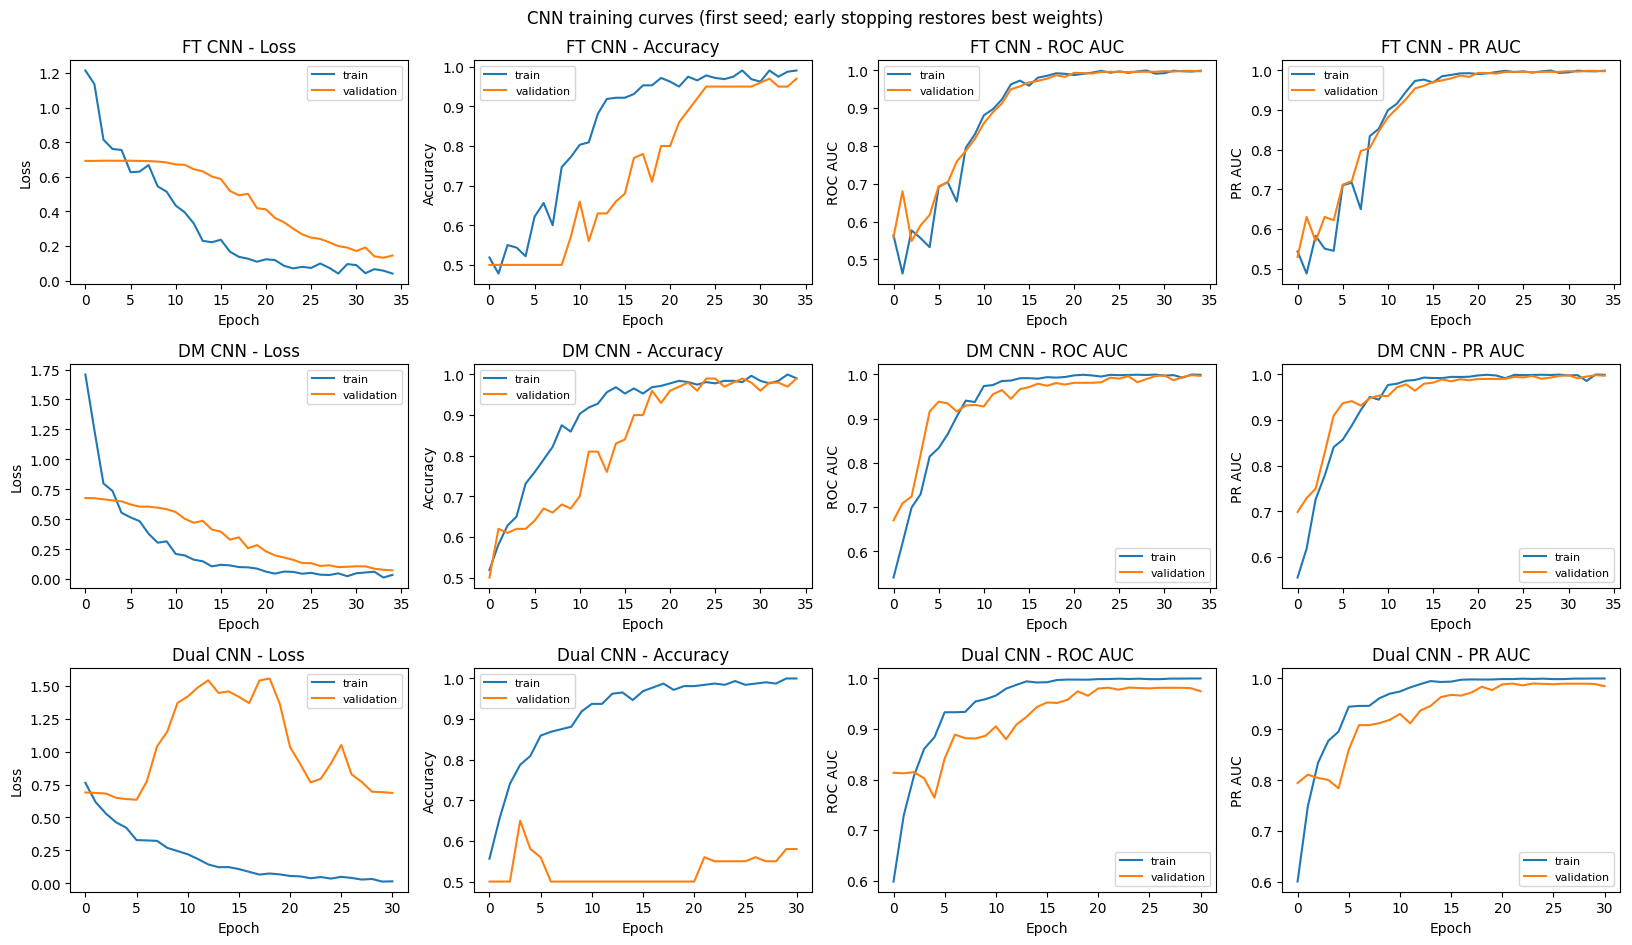

Saved cnn_training_curves.png


In [76]:
def _resolve_key(hist, base):
    """Find a history key for a metric base name, tolerating Keras suffixes."""
    if base in hist:
        return base
    for k in hist:
        if k.startswith("val_"):
            continue
        if k == base or k.split("_")[0] == base:
            return k
    return None


def plot_training_curves():
    panels = [("loss", "Loss"), ("accuracy", "Accuracy"),
              ("roc_auc", "ROC AUC"), ("pr_auc", "PR AUC")]
    names = [n for n in CNN_NAMES if n in cnn_histories]
    ncol = len(panels)
    fig, axes = plt.subplots(len(names), ncol, figsize=(4.1 * ncol, 3.2 * len(names)), squeeze=False)
    for r, name in enumerate(names):
        hist = cnn_histories[name]
        for c, (base, label) in enumerate(panels):
            ax = axes[r][c]
            tr_key = _resolve_key(hist, base)
            if tr_key is not None:
                ax.plot(hist[tr_key], label="train")
                va_key = "val_" + tr_key
                if va_key in hist:
                    ax.plot(hist[va_key], label="validation")
            ax.set_title(f"{name} - {label}")
            ax.set_xlabel("Epoch")
            ax.set_ylabel(label)
            ax.legend(fontsize=8)
    fig.suptitle("CNN training curves (first seed; early stopping restores best weights)")
    fig.tight_layout()
    fig.savefig(FIG_DIR / "cnn_training_curves.png", dpi=300, bbox_inches="tight")
    plt.show()


plot_training_curves()
print("Saved cnn_training_curves.png")


## 15.1. Training curves across seeds

This cell plots the training and validation curves of one CNN (set by `model_to_plot`) for every seed, to compare training stability between seeds.

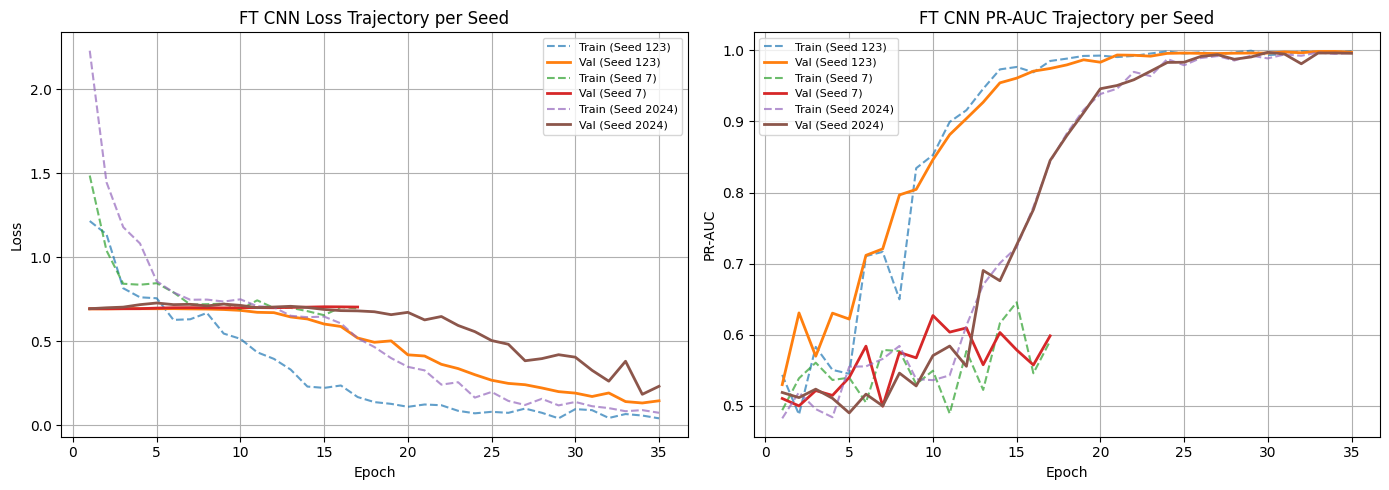

In [77]:
model_to_plot = "FT CNN"

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for seed, hist in cnn_seed_histories[model_to_plot].items():
    epochs = range(1, len(hist["loss"]) + 1)
    axes[0].plot(epochs, hist["loss"], label=f"Train (Seed {seed})", linestyle="--", alpha=0.7)
    axes[0].plot(epochs, hist["val_loss"], label=f"Val (Seed {seed})", linewidth=2)

axes[0].set_title(f"{model_to_plot} Loss Trajectory per Seed")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend(fontsize=8)
axes[0].grid(True)

for seed, hist in cnn_seed_histories[model_to_plot].items():
    epochs = range(1, len(hist["pr_auc"]) + 1)
    axes[1].plot(epochs, hist["pr_auc"], label=f"Train (Seed {seed})", linestyle="--", alpha=0.7)
    axes[1].plot(epochs, hist["val_pr_auc"], label=f"Val (Seed {seed})", linewidth=2)

axes[1].set_title(f"{model_to_plot} PR-AUC Trajectory per Seed")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("PR-AUC")
axes[1].legend(fontsize=8)
axes[1].grid(True)

plt.tight_layout()
plt.savefig(FIG_DIR / f"{model_to_plot.lower().replace(' ', '_')}_curves_per_seed.png")
plt.show()

## 16. Late-fusion diagnostic

This diagnostic averages the predicted probabilities of the FT and DM CNNs, using a weight chosen on the validation set. It tests whether simple late fusion of the two single-input models matches the dual-input CNN.

In [78]:
# Computes a weighted average of predicted probabilities from the FT CNN and DM CNN models.
ft_val = np.mean(
    [cnn_seed_probs[s]["FT CNN"]["val"] for s in SEED_LIST],
    axis=0,
)
dm_val = np.mean(
    [cnn_seed_probs[s]["DM CNN"]["val"] for s in SEED_LIST],
    axis=0,
)
ft_test = np.mean(
    [cnn_seed_probs[s]["FT CNN"]["test"] for s in SEED_LIST],
    axis=0,
)
dm_test = np.mean(
    [cnn_seed_probs[s]["DM CNN"]["test"] for s in SEED_LIST],
    axis=0,
)

weights = np.linspace(0.0, 1.0, 21)
val_aucs = [
    roc_auc_score(y_val, w * ft_val + (1.0 - w) * dm_val)
    for w in weights
]

best_w = float(weights[int(np.argmax(val_aucs))])
late_fusion_test = best_w * ft_test + (1.0 - best_w) * dm_test

print("=== Late-Fusion Diagnostic Results ===")
print(f"Validation-selected FT weight (w): {best_w:.2f} (DM weight: {1.0 - best_w:.2f})")
print(f"Late-fusion test ROC-AUC:         {roc_auc_score(y_test, late_fusion_test):.4f}")
print(f"Late-fusion test PR-AUC:          {average_precision_score(y_test, late_fusion_test):.4f}")

=== Late-Fusion Diagnostic Results ===
Validation-selected FT weight (w): 0.45 (DM weight: 0.55)
Late-fusion test ROC-AUC:         1.0000
Late-fusion test PR-AUC:          1.0000


## 17. Final holdout set

A final holdout set is built from background arrays that are not used in any development split. Once the holdout is defined, the pipeline is frozen: the seed-123 models and their validation-selected thresholds are evaluated on it once, and the models are not changed afterwards. These results are the final reported numbers.

In [79]:
CONFIG["FINAL_HOLDOUT_SEED"] = 999983       # never used anywhere else in this notebook
CONFIG["FINAL_HOLDOUT_N_BACKGROUND"] = 90
CONFIG["FINAL_HOLDOUT_POS"] = 100
CONFIG["FINAL_HOLDOUT_NEG"] = 100

def make_final_holdout_background_bank(n_backgrounds, seed):
    """Independent background bank for the final holdout. Prefers genuinely
    unused local cached arrays (ones never put into BACKGROUND_BANK);
    falls back to fresh procedural backgrounds under a brand-new seed."""
    holdout_rng = np.random.default_rng(seed)
    bank = []
    if BACKGROUND_MODE == "local_cached_arrays":
        used_ids = {s["original_id"] for s in BACKGROUND_SOURCE
                    if s["background_source"] == "local_cached_array"}
        unused = [i for i in range(len(local_backgrounds)) if i not in used_ids]
        holdout_rng.shuffle(unused)
        for i in unused[:n_backgrounds]:
            bank.append(resize_2d_nearest_interp(robust_zscore(local_backgrounds[i]), TARGET_FT_SHAPE))
        print(f"Final holdout: {len(bank)} previously-unused local background arrays reserved.")
    while len(bank) < n_backgrounds:
        bank.append(procedural_rfi_background(CONFIG["NFREQ"], CONFIG["NTIME"], holdout_rng))
    return np.stack(bank[:n_backgrounds], axis=0).astype(np.float32)

FINAL_HOLDOUT_BANK = make_final_holdout_background_bank(
    CONFIG["FINAL_HOLDOUT_N_BACKGROUND"], CONFIG["FINAL_HOLDOUT_SEED"]
)

def build_final_holdout_dataset(bank, n_pos, n_neg, seed):
    """Same construction as build_dataset_from_background_split, but it reads from
    an isolated bank and reuses the FROZEN dm_train_mean/dm_train_std"""
    rng = np.random.default_rng(seed)
    X_ft, X_dm, y, meta_rows = [], [], [], []

    for _ in range(n_neg):
        ft_bg = robust_zscore(bank[int(rng.integers(len(bank)))])
        dm_img = ft_to_dm_time_snr(ft_bg, DM_ALIGN)
        X_ft.append(to_unit_interval(ft_bg))
        X_dm.append(dm_img.astype(np.float32))
        y.append(0)
        meta_rows.append({"label": 0, "dm": np.nan, "snr": np.nan})

    for _ in range(n_pos):
        ft_bg = robust_zscore(bank[int(rng.integers(len(bank)))])
        ft_injected, inj_meta = inject_frb(ft_bg, FREQS_GHZ, CONFIG["DT_MS"], rng)
        dm_img = ft_to_dm_time_snr(ft_injected, DM_ALIGN)
        X_ft.append(to_unit_interval(ft_injected))
        X_dm.append(dm_img.astype(np.float32))
        y.append(1)
        meta_rows.append({"label": 1, "dm": inj_meta["dm"], "snr": inj_meta["snr"]})

    X_ft = np.stack(X_ft, axis=0).astype(np.float32)
    X_dm = np.stack(X_dm, axis=0).astype(np.float32)
    X_dm = ((X_dm - dm_train_mean) / dm_train_std).astype(np.float32)  # frozen stats
    y = np.array(y, dtype=int)
    meta = pd.DataFrame(meta_rows)

    perm = rng.permutation(len(y))
    return X_ft[perm], X_dm[perm], y[perm], meta.iloc[perm].reset_index(drop=True)

holdout_ft, holdout_dm, y_holdout, meta_holdout = build_final_holdout_dataset(
    FINAL_HOLDOUT_BANK, CONFIG["FINAL_HOLDOUT_POS"], CONFIG["FINAL_HOLDOUT_NEG"],
    CONFIG["FINAL_HOLDOUT_SEED"] + 1
)
print("Final holdout:", holdout_ft.shape, holdout_dm.shape, "positive fraction:", y_holdout.mean())

holdout_ft_cnn = holdout_ft[..., None]
holdout_dm_cnn = holdout_dm[..., None]
holdout_inputs = {"FT CNN": holdout_ft_cnn, "DM CNN": holdout_dm_cnn,
                   "Dual CNN": [holdout_ft_cnn, holdout_dm_cnn]}

holdout_rows = []
holdout_probs = {}
for name in ["FT CNN", "DM CNN", "Dual CNN"]:
    threshold = float(results_df.loc[results_df["model"] == name, "threshold_from_val"].iloc[0])
    probs = trained[name].predict_proba(holdout_inputs[name])[:, 1]
    holdout_probs[name] = probs
    holdout_rows.append(evaluate_probabilities(name, y_val, val_probs[name], y_holdout, probs))

holdout_results_df = pd.DataFrame(holdout_rows)
holdout_results_df['model_seed'] = 123
holdout_results_df.to_csv(TABLE_DIR / "final_holdout_results.csv", index=False)
holdout_results_df

Final holdout: 90 previously-unused local background arrays reserved.
Final holdout: (200, 128, 128) (200, 40, 128) positive fraction: 0.5


,model,model_family,threshold_from_val,accuracy,precision,recall,f1,roc_auc,pr_auc,false_positive_rate,true_negative,false_positive,false_negative,true_positive,model_seed
0,FT CNN,CNN,0.442480,0.990,1.000000,0.98,0.989899,1.0000,1.000000,0.00,100,0,2,98,123
1,DM CNN,CNN,0.882932,0.970,0.979592,0.96,0.969697,0.9953,0.995841,0.02,98,2,4,96,123
2,Dual CNN,CNN,0.990049,0.885,0.840708,0.95,0.892019,0.9533,0.954361,0.18,82,18,5,95,123


## 18. ROC and precision-recall curves

ROC and precision-recall curves for the FT, DM and Dual CNNs on the final holdout set (seed-123 models), showing performance across decision thresholds.

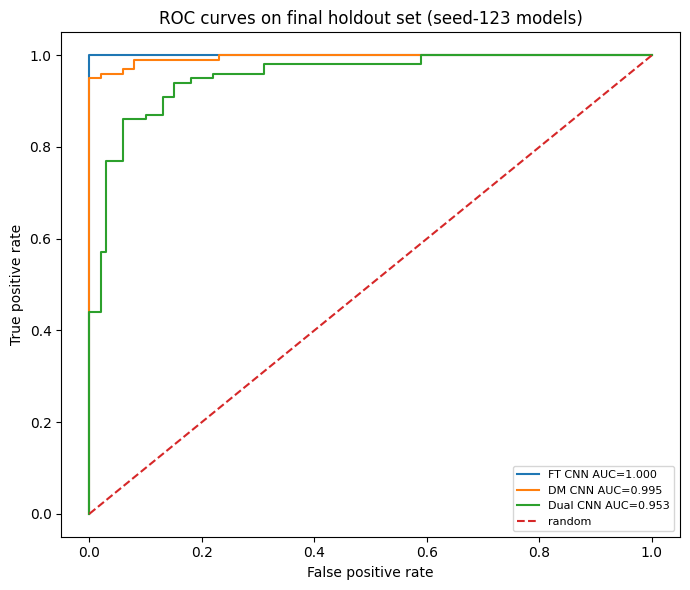

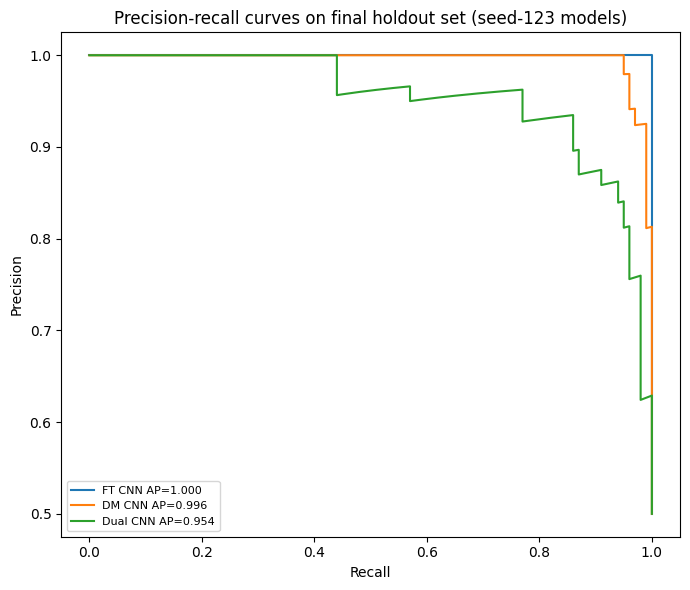

In [80]:
def plot_model_curves():
    # ROC curves.
    plt.figure(figsize=(7, 6))
    for name, p in holdout_probs.items():
        fpr, tpr, _ = roc_curve(y_holdout, p)
        auc = roc_auc_score(y_holdout, p)
        plt.plot(fpr, tpr, label=f"{name} AUC={auc:.3f}")
    plt.plot([0, 1], [0, 1], linestyle="--", label="random")
    plt.xlabel("False positive rate")
    plt.ylabel("True positive rate")
    plt.title("ROC curves on final holdout set (seed-123 models)")
    plt.legend(fontsize=8)
    plt.tight_layout()
    plt.savefig(FIG_DIR / "roc_curves.png", dpi=300, bbox_inches="tight")
    plt.show()

    # Precision-recall curves.
    plt.figure(figsize=(7, 6))
    for name, p in holdout_probs.items():
        prec, rec, _ = precision_recall_curve(y_holdout, p)
        ap = average_precision_score(y_holdout, p)
        plt.plot(rec, prec, label=f"{name} AP={ap:.3f}")
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title("Precision-recall curves on final holdout set (seed-123 models)")
    plt.legend(fontsize=8)
    plt.tight_layout()
    plt.savefig(FIG_DIR / "precision_recall_curves.png", dpi=300, bbox_inches="tight")
    plt.show()

plot_model_curves()

## 19. Confusion matrices for the three CNNs

Confusion matrices give the detection counts (true positives, false positives, true negatives and false negatives) for the FT, DM and Dual CNNs on the final holdout set, using each model's validation-selected threshold. Each cell shows the raw count and its percentage of the holdout set.

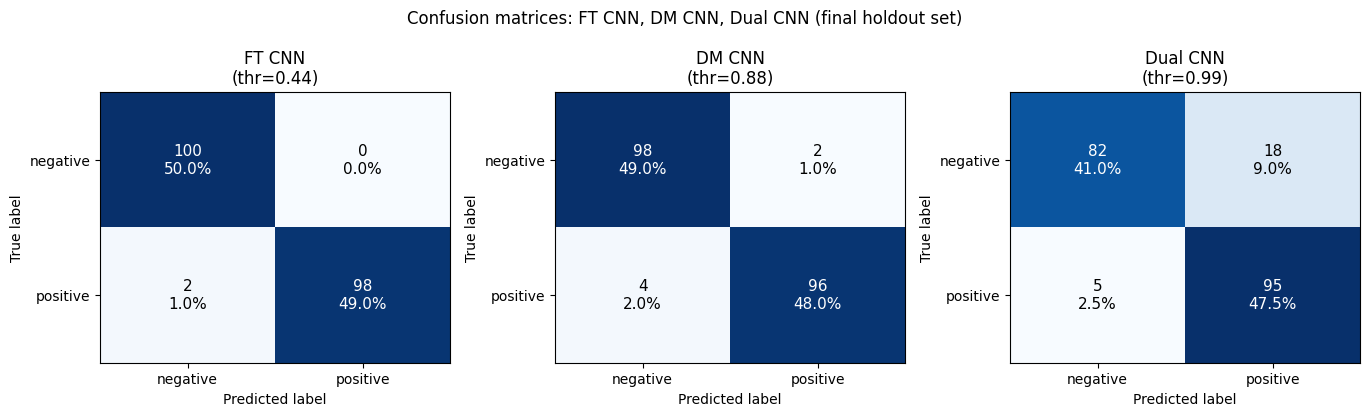

Saved confusion_matrices_cnns.png and individual confusion_matrix_*.png for: FT CNN, DM CNN, Dual CNN


In [81]:
CNN_MODELS_FOR_PLOTS = ["FT CNN", "DM CNN", "Dual CNN"]


def confusion_for(name):
    """Confusion matrix for a model using its validation-selected threshold."""
    threshold = float(results_df.loc[results_df["model"] == name, "threshold_from_val"].iloc[0])
    pred = (holdout_probs[name] >= threshold).astype(int)
    return confusion_matrix(y_holdout, pred), threshold


def annotate_confusion(ax, cm, title):
    ax.imshow(cm, aspect="auto", cmap="Blues")
    ax.set_title(title)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["negative", "positive"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["negative", "positive"])
    total = cm.sum()
    thresh = cm.max() / 2.0 if cm.max() > 0 else 0.5
    for r in range(2):
        for c in range(2):
            count = int(cm[r, c])
            pct = (100.0 * count / total) if total else 0.0
            ax.text(c, r, f"{count}\n{pct:.1f}%", ha="center", va="center",
                    color="white" if cm[r, c] > thresh else "black", fontsize=11)


# Only plot CNNs that actually produced predictions.
available_cnns = [n for n in CNN_MODELS_FOR_PLOTS if n in holdout_probs]
missing_cnns = [n for n in CNN_MODELS_FOR_PLOTS if n not in holdout_probs]
if missing_cnns:
    print("Warning: no predictions found for:", missing_cnns)

# Combined 1 x 3 figure for the three CNNs.
fig, axes = plt.subplots(1, len(available_cnns), figsize=(4.6 * len(available_cnns), 4.2), squeeze=False)
for j, name in enumerate(available_cnns):
    cm, thr = confusion_for(name)
    annotate_confusion(axes[0][j], cm, f"{name}\n(thr={thr:.2f})")
fig.suptitle("Confusion matrices: FT CNN, DM CNN, Dual CNN (final holdout set)")
fig.tight_layout()
fig.savefig(FIG_DIR / "confusion_matrices_cnns.png", dpi=300, bbox_inches="tight")
plt.show()

# Also save each CNN confusion matrix individually.
for name in available_cnns:
    cm, thr = confusion_for(name)
    fig_i, ax_i = plt.subplots(figsize=(4.5, 4))
    annotate_confusion(ax_i, cm, f"{name} (thr={thr:.2f})")
    fig_i.tight_layout()
    safe_name = name.lower().replace(" ", "_")
    fig_i.savefig(FIG_DIR / f"confusion_matrix_{safe_name}.png", dpi=300, bbox_inches="tight")
    plt.close(fig_i)

print("Saved confusion_matrices_cnns.png and individual confusion_matrix_*.png for:",
      ", ".join(available_cnns))

## 20. Detection efficiency versus injected SNR

Detection efficiency is the fraction of injected positives recovered in each SNR bin, so it is defined only for positive samples (only positives have an injected SNR). The three CNNs are overlaid on a single plot using the same SNR bins, evaluated on the final holdout set.

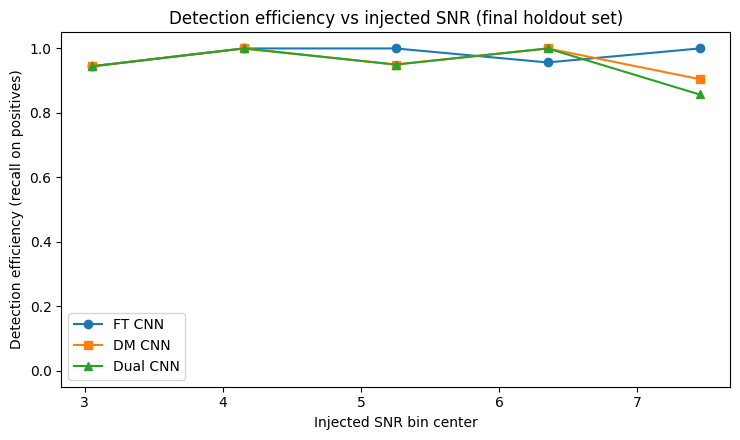

Saved detection_efficiency_cnns.png and detection_efficiency_cnns.csv


,model,snr_low,snr_high,snr_center,n_positive,detection_efficiency
0,FT CNN,2.5,3.6,3.05,18,0.944444
1,FT CNN,3.6,4.7,4.15,18,1.000000
2,FT CNN,4.7,5.8,5.25,20,1.000000
3,FT CNN,5.8,6.9,6.35,23,0.956522
4,FT CNN,6.9,8.0,7.45,21,1.000000
5,DM CNN,2.5,3.6,3.05,18,0.944444
6,DM CNN,3.6,4.7,4.15,18,1.000000
7,DM CNN,4.7,5.8,5.25,20,0.950000
8,DM CNN,5.8,6.9,6.35,23,1.000000
9,DM CNN,6.9,8.0,7.45,21,0.904762


In [82]:
# Shared SNR bins across all three CNNs (so the curves are directly comparable).
SNR_BINS = np.linspace(CONFIG["SNR_RANGE"][0], CONFIG["SNR_RANGE"][1], 6)


def detection_efficiency_by_snr(model_name, bins=SNR_BINS):
    """Fraction of injected positives recovered in each SNR bin, for one model."""
    threshold = float(results_df.loc[results_df["model"] == model_name, "threshold_from_val"].iloc[0])
    pred = (holdout_probs[model_name] >= threshold).astype(int)

    snr = meta_holdout["snr"].to_numpy(dtype=float)
    label = meta_holdout["label"].to_numpy(dtype=int)
    mask = label == 1

    rows = []
    for lo, hi in zip(bins[:-1], bins[1:]):
        m = mask & (snr >= lo) & (snr < hi)
        n = int(np.sum(m))
        eff = float(np.mean(pred[m] == 1)) if n > 0 else np.nan
        rows.append({
            "model": model_name,
            "snr_low": float(lo),
            "snr_high": float(hi),
            "snr_center": float((lo + hi) / 2.0),
            "n_positive": n,
            "detection_efficiency": eff,
        })
    return pd.DataFrame(rows)


CNN_MODELS_FOR_PLOTS = ["FT CNN", "DM CNN", "Dual CNN"]
available_cnns = [n for n in CNN_MODELS_FOR_PLOTS if n in holdout_probs]

# One plot comparing all three CNNs on the same SNR bins.
combined_eff = pd.concat(
    [detection_efficiency_by_snr(name) for name in available_cnns], ignore_index=True
)
combined_eff.to_csv(TABLE_DIR / "detection_efficiency_cnns.csv", index=False)

plt.figure(figsize=(7.5, 4.5))
markers = {"FT CNN": "o", "DM CNN": "s", "Dual CNN": "^"}
for name in available_cnns:
    sub = detection_efficiency_by_snr(name).dropna(subset=["detection_efficiency"])
    plt.plot(sub["snr_center"], sub["detection_efficiency"],
             marker=markers.get(name, "o"), label=name)
plt.xlabel("Injected SNR bin center")
plt.ylabel("Detection efficiency (recall on positives)")
plt.title("Detection efficiency vs injected SNR (final holdout set)")
plt.ylim(-0.05, 1.05)
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "detection_efficiency_cnns.png", dpi=300, bbox_inches="tight")
plt.show()

print("Saved detection_efficiency_cnns.png and detection_efficiency_cnns.csv")
combined_eff

## 21. Hard-negative stress test

This cell evaluates the CNNs on small sets of hard negatives: broadband impulsive RFI, narrowband transients, linear chirps, and sweeps that follow a power law other than the cold-plasma dispersion law. It tests whether the models, and the DM CNN in particular, respond to physical dispersion structure rather than to any sweep-like pattern. Hard negatives are used for evaluation only and are not used in training.

In [83]:
def hard_negative_broadband_impulsive(nfreq, ntime, rng):
    bg = procedural_rfi_background(nfreq, ntime, rng)
    t0 = rng.integers(ntime // 4, 3 * ntime // 4)
    amp = rng.uniform(2.5, 4.5)
    bg[:, max(0, t0 - 1):t0 + 2] += amp * rng.uniform(0.6, 1.3, (nfreq, 1))
    return bg

def hard_negative_narrowband_transient(nfreq, ntime, rng):
    bg = procedural_rfi_background(nfreq, ntime, rng)
    ch0 = rng.integers(0, nfreq - 10)
    ch1 = ch0 + rng.integers(3, 10)
    t0 = rng.integers(ntime // 4, 3 * ntime // 4)
    amp = rng.uniform(2.0, 4.0)
    bg[ch0:ch1, max(0, t0 - 2):t0 + 3] += amp
    return bg

def hard_negative_linear_chirp(nfreq, ntime, rng, freqs_ghz):
    bg = procedural_rfi_background(nfreq, ntime, rng)
    slope = rng.uniform(0.5, 1.5) * ntime / nfreq
    t0 = rng.integers(ntime // 4, ntime // 2)
    amp = rng.uniform(2.0, 4.0)
    for ch in range(nfreq):
        t_center = int(t0 + slope * ch)
        if 0 <= t_center < ntime:
            bg[ch, max(0, t_center - 1):t_center + 2] += amp
    return bg

def hard_negative_wrong_power_law(nfreq, ntime, rng, freqs_ghz, exponent):
    bg = procedural_rfi_background(nfreq, ntime, rng)
    ref = freqs_ghz.max()
    delay = (freqs_ghz ** (-exponent) - ref ** (-exponent))
    delay = delay / delay.max() * (ntime * 0.4)
    t0 = ntime // 3
    amp = rng.uniform(2.0, 4.0)
    for ch in range(nfreq):
        t_center = int(t0 + delay[ch])
        if 0 <= t_center < ntime:
            bg[ch, max(0, t_center - 1):t_center + 2] += amp
    return bg


def build_hard_negative_set(n_each, seed):
    rng = np.random.default_rng(seed)
    generators = {
        "broadband_impulsive": lambda: hard_negative_broadband_impulsive(CONFIG["NFREQ"], CONFIG["NTIME"], rng),
        "narrowband_transient": lambda: hard_negative_narrowband_transient(CONFIG["NFREQ"], CONFIG["NTIME"], rng),
        "linear_chirp": lambda: hard_negative_linear_chirp(CONFIG["NFREQ"], CONFIG["NTIME"], rng, FREQS_GHZ),
        "power_law_-1": lambda: hard_negative_wrong_power_law(CONFIG["NFREQ"], CONFIG["NTIME"], rng, FREQS_GHZ, 1.0),
        "power_law_-4": lambda: hard_negative_wrong_power_law(CONFIG["NFREQ"], CONFIG["NTIME"], rng, FREQS_GHZ, 4.0),
    }
    X_ft, X_dm, kinds = [], [], []
    for kind, gen in generators.items():
        for _ in range(n_each):
            ft = robust_zscore(gen())
            dm_img = ft_to_dm_time_snr(ft, DM_ALIGN)
            X_ft.append(to_unit_interval(ft))
            X_dm.append(dm_img.astype(np.float32))
            kinds.append(kind)
    X_ft = np.stack(X_ft).astype(np.float32)
    X_dm = ((np.stack(X_dm).astype(np.float32) - dm_train_mean) / dm_train_std).astype(np.float32)
    return X_ft, X_dm, np.array(kinds)

hardneg_ft, hardneg_dm, hardneg_kind = build_hard_negative_set(n_each=40, seed=SEED + 5)
y_hardneg = np.zeros(len(hardneg_kind), dtype=int)  # all true negatives

hardneg_ft_cnn = hardneg_ft[..., None]
hardneg_dm_cnn = hardneg_dm[..., None]

hardneg_results = []
for name, X, threshold_col in [
    ("FT CNN", hardneg_ft_cnn, "threshold_from_val"),
    ("DM CNN", hardneg_dm_cnn, "threshold_from_val"),
    ("Dual CNN", [hardneg_ft_cnn, hardneg_dm_cnn], "threshold_from_val"),
]:
    threshold = float(results_df.loc[results_df["model"] == name, threshold_col].iloc[0])
    probs = trained[name].predict_proba(X)[:, 1]
    pred = (probs >= threshold).astype(int)
    for kind in np.unique(hardneg_kind):
        mask = hardneg_kind == kind
        false_positive_rate = pred[mask].mean()  # fraction wrongly called positive
        hardneg_results.append({"model": name, "hard_negative_type": kind,
                                 "n": int(mask.sum()), "false_positive_rate": float(false_positive_rate)})

hardneg_df = pd.DataFrame(hardneg_results)
hardneg_df.to_csv(TABLE_DIR / "hard_negative_robustness.csv", index=False)
print(hardneg_df.pivot(index="hard_negative_type", columns="model", values="false_positive_rate"))

model                 DM CNN  Dual CNN  FT CNN
hard_negative_type                            
broadband_impulsive     0.50     0.725   0.975
linear_chirp            0.20     0.475   0.300
narrowband_transient    0.25     0.500   0.650
power_law_-1            1.00     1.000   1.000
power_law_-4            1.00     1.000   1.000


## 22. Claim boundary

This cell records which claims the run supports and which it does not, and writes a small table and notes file. A confirmed astrophysical FRB detection requires real filterbank data with valid metadata and separate validation, so that claim is marked as not supported by this notebook alone. The background-source claim depends on `BACKGROUND_MODE`: it is supported only when real local background arrays were used.

In [84]:
claim_rows = []

# Background-source claim, keyed off what this run actually used.
if BACKGROUND_MODE == "local_cached_arrays":
    background_supported = True
    background_note = (
        "This run used local cached background arrays. The Methods section may describe the "
        "background source only if those local files are documented and are actually the claimed "
        "(e.g. HERA/RFI) backgrounds."
    )
else:
    background_supported = False
    background_note = (
        "This run used procedurally simulated RFI-like backgrounds. The paper must NOT describe "
        "these exact results as HERA-derived, CSIRO-derived, or ASKAP-derived."
    )
claim_rows.append({
    "claim_type": "background_source_as_real_observatory_data",
    "supported": background_supported,
    "note": background_note,
})

# Controlled injection benchmark -- this is what the notebook genuinely supports.
claim_rows.append({
    "claim_type": "controlled_injection_benchmark",
    "supported": True,
    "note": ("Supported: the notebook evaluates models on a controlled benchmark of injected "
             "dispersed FRB-like signals versus background/RFI-like samples, with a fixed split, "
             "validation-selected thresholds, and multi-seed CNN metrics."),
})

# Confirmed astrophysical FRB detection -- NOT supported here.
claim_rows.append({
    "claim_type": "confirmed_astrophysical_frb_detection",
    "supported": False,
    "note": ("Not supported by this notebook alone. Requires real local .fil/.fil.gz files with "
             "valid event metadata, successful on-burst recovery, and off-burst controls in the "
             "separate local filterbank validation notebooks."),
})

# Fully validated CSIRO/ASKAP end-to-end pipeline -- NOT supported here.
claim_rows.append({
    "claim_type": "fully_validated_csiro_askap_end_to_end_pipeline",
    "supported": False,
    "note": ("Not supported by this notebook alone. Requires successful local filterbank "
             "processing with valid metadata, positive and off-burst controls, and end-to-end "
             "validation metrics from the CSIRO/ASKAP validation notebook."),
})

claim_gate_df = pd.DataFrame(claim_rows)
claim_gate_df.to_csv(TABLE_DIR / "claim_gate.csv", index=False)

with open(TEXT_DIR / "claim_gate_notes.md", "w", encoding="utf-8") as f:
    f.write("# claim gate notes\n\n")
    f.write(f"Background mode for this run: `{BACKGROUND_MODE}`\n\n")
    for _, row in claim_gate_df.iterrows():
        f.write(f"## {row['claim_type']}\n")
        f.write(f"Supported: {row['supported']}\n\n")
        f.write(f"{row['note']}\n\n")

print("Claim gate for this run:")
for _, row in claim_gate_df.iterrows():
    flag = "OK " if row["supported"] else "NO "
    print(f"  [{flag}] {row['claim_type']}")
print("\nSaved claim_gate.csv and claim_gate_notes.md")
claim_gate_df


Claim gate for this run:
  [OK ] background_source_as_real_observatory_data
  [OK ] controlled_injection_benchmark
  [NO ] confirmed_astrophysical_frb_detection
  [NO ] fully_validated_csiro_askap_end_to_end_pipeline

Saved claim_gate.csv and claim_gate_notes.md


,claim_type,supported,note
0,background_source_as_real_observatory_data,True,This run used local cached background arrays. ...
1,controlled_injection_benchmark,True,Supported: the notebook evaluates models on a ...
2,confirmed_astrophysical_frb_detection,False,Not supported by this notebook alone. Requires...
3,fully_validated_csiro_askap_end_to_end_pipeline,False,Not supported by this notebook alone. Requires...


## 23. Consolidated results file

This cell collects the dataset counts, injection ranges, CNN metrics, confusion-matrix counts and SNR-bin efficiencies into a single `paper_values.csv` for reporting.

In [85]:
paper_values = {}

# Dataset counts.
paper_values["n_background_bank"] = CONFIG["N_BACKGROUND_BANK"]
paper_values["n_train"] = int(CONFIG["TRAIN_POS"] + CONFIG["TRAIN_NEG"])
paper_values["n_val"] = int(CONFIG["VAL_POS"] + CONFIG["VAL_NEG"])
paper_values["n_test"] = int(CONFIG["TEST_POS"] + CONFIG["TEST_NEG"])
paper_values["nfreq"] = CONFIG["NFREQ"]
paper_values["ntime"] = CONFIG["NTIME"]
paper_values["n_dm_trials"] = CONFIG["N_DM_TRIALS"]
paper_values["background_mode"] = BACKGROUND_MODE

# Injection ranges.
paper_values["dm_range_min"], paper_values["dm_range_max"] = CONFIG["DM_RANGE"]
paper_values["snr_range_min"], paper_values["snr_range_max"] = CONFIG["SNR_RANGE"]

# CNN metrics.
for name in ["FT CNN", "DM CNN", "Dual CNN"]:
    sub = cnn_seed_metrics_df[cnn_seed_metrics_df["model"] == name]
    for metric in ["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]:
        sd = sub[metric].std()
        sd = 0.0 if pd.isna(sd) else sd
        safe_name = name.lower().replace(" ", "_")
        paper_values[f"{safe_name}_{metric}_mean"] = round(float(sub[metric].mean()), 4)
        paper_values[f"{safe_name}_{metric}_std"] = round(float(sd), 4)

# Confusion matrix counts for each CNN.
for name in ["FT CNN", "DM CNN", "Dual CNN"]:
    row = holdout_results_df[holdout_results_df["model"] == name].iloc[0]
    safe_name = name.lower().replace(" ", "_")
    for col in ["true_negative", "false_positive", "false_negative", "true_positive", "threshold_from_val"]:
        paper_values[f"{safe_name}_{col}"] = row[col]

# SNR-bin detection efficiency.
for _, row in combined_eff.iterrows():
    safe_name = row["model"].lower().replace(" ", "_")
    paper_values[f"{safe_name}_snr_{row['snr_low']:.1f}_{row['snr_high']:.1f}_efficiency"] = row["detection_efficiency"]

paper_values_df = pd.DataFrame([paper_values]).T.reset_index()
paper_values_df.columns = ["key", "value"]
paper_values_df.to_csv(TABLE_DIR / "paper_values.csv", index=False)
print(f"Saved paper_values.csv with {len(paper_values_df)} entries")
paper_values_df

Saved paper_values.csv with 78 entries


,key,value
0,n_background_bank,360
1,n_train,320
2,n_val,100
3,n_test,160
4,nfreq,128
...,...,...
73,dual_cnn_snr_2.5_3.6_efficiency,0.944444
74,dual_cnn_snr_3.6_4.7_efficiency,1.0
75,dual_cnn_snr_4.7_5.8_efficiency,0.95
76,dual_cnn_snr_5.8_6.9_efficiency,1.0


## 24. Output files

After the notebook runs, outputs are written under `results/`.

**Tables (`tables/`)**
- `model_results_all_models.csv` - every model, sorted by PR-AUC
- `model_results_cnn_main_table.csv` - the three CNNs (main comparison)
- `model_results_baseline_secondary_table.csv` - classical baselines
- `cnn_seed_metrics.csv` - per-seed CNN metrics
- `cnn_metric_summary.csv` - CNN mean and standard deviation across seeds
- `final_holdout_results.csv` - CNN metrics on the final holdout set
- `training_history_*.csv` - per-epoch history for each CNN (first seed)
- `dataset_metadata.csv`, `dataset_provenance.csv`, `background_split_check.csv` - sample labels and injected parameters, data source, and split-overlap check
- `dm_pipeline_unit_check.csv`, `dm_time_sanity_check.csv` - DM-transform checks and injected vs recovered DM
- `detection_efficiency_cnns.csv` - detection efficiency vs SNR for all three CNNs
- `hard_negative_robustness.csv` - false-positive rates on hard negatives
- `claim_gate.csv`, `paper_values.csv` - claim boundary and consolidated values

**Figures (`figures/`)**
- `example_positive_ft_dm.png`, `example_negative_ft_dm.png`
- `dm_time_sanity_check.png`, `target_vs_measured_snr.png`
- `cnn_training_curves.png` and `*_curves_per_seed.png`
- `roc_curves.png`, `precision_recall_curves.png`
- `confusion_matrices_cnns.png` plus one confusion-matrix file per CNN
- `detection_efficiency_cnns.png`

**Text (`paper_text/`)**
- `model_summary_*.txt` - architecture summaries
- `claim_gate_notes.md`

### Interpretation notes

- The description of the data source must match `BACKGROUND_MODE`. If a run used procedurally simulated backgrounds, its results must be described as simulated.
- CNN development metrics are reported as mean +/- standard deviation across `CONFIG["SEED_LIST"]`, with exact sample counts and injected DM and SNR ranges. Final holdout metrics use the seed-123 models.
- This notebook provides a controlled injection benchmark. It does not establish a confirmed astrophysical FRB detection, which requires real filterbank data with valid metadata.

### Runtime note

Multi-seed CNN training with early stopping is the slowest part. For a quick single pass set `CONFIG["SEED_LIST"] = [123]`; use the full list for the mean +/- standard deviation reported in the paper. Deterministic ops are enabled for reproducibility and can be disabled for speed.